# Deep Armocromia RGB-M — Master Experiment Notebook

Notebook ini dibuat untuk dipakai sebagai **SATU Kaggle Code dengan banyak Version**.

Contoh histori:

| Experiment | Kaggle Version | Perubahan utama | Accuracy | Macro Recall | Macro F1 | Top-3 | Kesimpulan |
|---|---|---|---:|---:|---:|---:|---|
| E0 | V1 | Full fine-tuning baseline | 30.59% | 28.09% | 27.00% | 63.49% | Baseline awal; overfitting kuat |
| E1+E2 | V2 | 3 blocks + deeper head | 26.86% | 24.35% | 23.97% | 61.84% | Terlalu restrictive |
| E3 | V3 | CelebA-only validation + 5 blocks | isi setelah run | isi | isi | isi | isi setelah run |
| E4 | V4 | Foreground crop | - | - | - | - | planned |
| E5 | V5 | Mild color augmentation | - | - | - | - | planned |
| E6 | V6 | Hierarchical 4+12 class | - | - | - | - | planned |

## Kenapa cleaning dan preprocessing tetap ada?

Setiap **Save & Run All** pada Kaggle menjalankan notebook dari runtime baru. Input private
Deep Armocromia tetap merupakan source awal, sedangkan `/kaggle/working` tidak dianggap sebagai
clean dataset permanen antar-runtime.

Karena itu pada setiap version kita tetap menjalankan:

```text
raw/private input
→ extraction
→ annotation audit
→ path/corrupt validation
→ cleaning
→ leakage check
→ split
→ preprocessing
→ training
→ official test
```

Yang boleh dilewati pada version berikutnya adalah **EDA visual tambahan** seperti gallery dan
plot yang hanya untuk dokumentasi. Audit integritas data tetap dijalankan.

## Kaggle Secret

Buat dan aktifkan secret:

```text
DEEP_ARMO_PASSWORD
```

Value = password resmi `RGB-M.zip`.

> Untuk eksperimen resmi gunakan **Save & Run All**, bukan hanya Quick Save.

In [1]:
# ============================================================
# 1. IMPORT LIBRARY & REPRODUCIBILITY
# ============================================================

import os
import sys
import json
import math
import random
import shutil
import hashlib
import subprocess
import warnings
from pathlib import Path
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

ImageFile.LOAD_TRUNCATED_IMAGES = False

print("Python       :", sys.version.split()[0])
print("Kaggle input :", Path("/kaggle/input").exists())
print("Setup selesai.")

Python       : 3.13.15
Kaggle input : True
Setup selesai.


## MASTER CONFIG — bagian utama yang diubah untuk Version berikutnya

Untuk E4/E5, sebisa mungkin ubah **cell ini saja** agar eksperimen tetap terkontrol.

`RUN_FULL_EDA=False` hanya mematikan visualisasi tambahan. Cleaning, hash check, split,
preprocessing, dan sanity check tetap berjalan.

In [2]:
# ============================================================
# MASTER EXPERIMENT CONFIG
# ============================================================

EXPERIMENT_ID = "E3"
EXPERIMENT_NAME = "Source-Aware CelebA Validation + 5-Block Fine-Tuning"

EXPERIMENT_HYPOTHESIS = (
    "CelebA-only validation yang lebih dekat dengan official test, "
    "dikombinasikan dengan 5-block fine-tuning, diharapkan meningkatkan "
    "generalization dibanding E0 dan E1+E2."
)

EXPECTED_ADVANTAGE = (
    "Checkpoint selection lebih sesuai dengan domain official test; "
    "kapasitas adaptasi lebih besar daripada eksperimen 3-block."
)

KNOWN_RISK = (
    "CelebA-only validation mengurangi CelebA training pool dan model masih "
    "dapat overfit apabila 5-block fine-tuning terlalu agresif."
)

# ------------------------------
# EDA / audit controls
# ------------------------------
RUN_FULL_EDA = True
RUN_MASK_AUDIT = True
RUN_DHASH_SCREENING = True

# ------------------------------
# Split
# ------------------------------
VALIDATION_STRATEGY = "celeba_only"
VAL_FRACTION_OF_OFFICIAL_TRAIN = 0.15

# ------------------------------
# Preprocessing / augmentation
# ------------------------------
USE_FOREGROUND_CROP = False
USE_MILD_COLOR_AUG = False

# ------------------------------
# Model / training
# ------------------------------
DROPOUT = 0.40

STAGE1_EPOCHS = 4
HEAD_LR = 8e-4

UNFREEZE_LAST_N_BLOCKS = 5
BACKBONE_LR = 3e-5
CLASSIFIER_LR = 2e-4

WEIGHT_DECAY = 4e-4
MAX_FINETUNE_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 6

print("=" * 80)
print("EXPERIMENT :", EXPERIMENT_ID)
print("NAME       :", EXPERIMENT_NAME)
print("HYPOTHESIS :", EXPERIMENT_HYPOTHESIS)
print("FULL EDA   :", RUN_FULL_EDA)
print("VAL MODE   :", VALIDATION_STRATEGY)
print("CROP       :", USE_FOREGROUND_CROP)
print("COLOR AUG  :", USE_MILD_COLOR_AUG)
print("UNFREEZE   :", UNFREEZE_LAST_N_BLOCKS)
print("=" * 80)

EXPERIMENT : E3
NAME       : Source-Aware CelebA Validation + 5-Block Fine-Tuning
HYPOTHESIS : CelebA-only validation yang lebih dekat dengan official test, dikombinasikan dengan 5-block fine-tuning, diharapkan meningkatkan generalization dibanding E0 dan E1+E2.
FULL EDA   : True
VAL MODE   : celeba_only
CROP       : False
COLOR AUG  : False
UNFREEZE   : 5


## 2. Deteksi mode dataset

Notebook memprioritaskan **dataset RGB-M yang sudah diekstrak**.

Kriteria prepared dataset:
- memiliki `annotations.csv`;
- pada folder yang sama terdapat folder `RGB-M/`.

Jika tidak ditemukan, notebook mencari source dataset lama yang memiliki:
- `annotations.csv`;
- `RGB-M.zip`.

In [3]:
# ============================================================
# 2. AUTO-DETECT PREPARED DATASET / ENCRYPTED SOURCE DATASET
# ============================================================

KAGGLE_INPUT = Path("/kaggle/input")
WORK_PREPARED_ROOT = Path("/kaggle/working/deep_armocromia_prepared")

assert KAGGLE_INPUT.exists(), "/kaggle/input tidak ditemukan."

annotation_candidates = list(KAGGLE_INPUT.rglob("annotations.csv"))

print(f"annotations.csv ditemukan: {len(annotation_candidates)}")
for i, p in enumerate(annotation_candidates):
    print(f"[{i}] {p}")

# --- Prioritas 1: prepared extracted dataset ---
prepared_matches = []
for ann in annotation_candidates:
    root = ann.parent
    if (root / "RGB-M").is_dir():
        prepared_matches.append((root, ann))

# --- Prioritas 2: source dataset dengan encrypted RGB-M.zip ---
source_matches = []
for ann in annotation_candidates:
    root = ann.parent
    if (root / "RGB-M.zip").is_file():
        source_matches.append((root, ann, root / "RGB-M.zip"))

if prepared_matches:
    MODE = "PREPARED_INPUT"
    DATA_ROOT, ANNOTATION_PATH = prepared_matches[0]
    RGBM_ZIP = None

    print("\n✅ MODE: PREPARED_INPUT")
    print("Dataset sudah diekstrak.")
    print("Password/extraction TIDAK diperlukan.")

elif source_matches:
    MODE = "ENCRYPTED_SOURCE"
    SOURCE_ROOT, ANNOTATION_PATH, RGBM_ZIP = source_matches[0]
    DATA_ROOT = WORK_PREPARED_ROOT

    print("\n⚠️ MODE: ENCRYPTED_SOURCE")
    print("Prepared dataset belum ditemukan.")
    print("RGB-M akan diekstrak satu kali ke /kaggle/working.")

else:
    raise FileNotFoundError(
        "Tidak ditemukan prepared RGB-M dataset maupun source RGB-M.zip. "
        "Pastikan private dataset Deep Armocromia sudah di-attach."
    )

print("\nMODE            :", MODE)
print("ANNOTATION_PATH :", ANNOTATION_PATH)
print("DATA_ROOT       :", DATA_ROOT)
if RGBM_ZIP is not None:
    print("RGBM_ZIP        :", RGBM_ZIP)

annotations.csv ditemukan: 1
[0] /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/annotations.csv

⚠️ MODE: ENCRYPTED_SOURCE
Prepared dataset belum ditemukan.
RGB-M akan diekstrak satu kali ke /kaggle/working.

MODE            : ENCRYPTED_SOURCE
ANNOTATION_PATH : /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/annotations.csv
DATA_ROOT       : /kaggle/working/deep_armocromia_prepared
RGBM_ZIP        : /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/RGB-M.zip


In [4]:
# ============================================================
# 3. LOAD ANNOTATIONS & KONFIGURASI KOLOM
# ============================================================

df = pd.read_csv(ANNOTATION_PATH)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Kolom resmi yang digunakan pada pipeline ini
SEASON_COL = "class"
SUBCLASS_COL = "sub_class"
PARTITION_COL = "partition"
MASKED_PATH_COL = "path_rgb_masked"

required_cols = [
    SEASON_COL,
    SUBCLASS_COL,
    PARTITION_COL,
    MASKED_PATH_COL,
]

missing_cols = [c for c in required_cols if c not in df.columns]
assert not missing_cols, f"Kolom wajib tidak ditemukan: {missing_cols}"

# Standardisasi teks tanpa mengubah makna label
for col in [SEASON_COL, SUBCLASS_COL, PARTITION_COL]:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
    )

df["joint_label"] = df[SEASON_COL] + "_" + df[SUBCLASS_COL]

EXPECTED_IMAGES = len(df)

display(df.head())

print("\nTotal annotation:", EXPECTED_IMAGES)

Shape: (4920, 7)

Columns:
['class', 'sub_class', 'partition', 'celeba', 'path_rgb_original', 'path_rgb_masked', 'path_mask']


,class,sub_class,partition,celeba,path_rgb_original,path_rgb_masked,path_mask,joint_label
0,autunno,deep,train,True,RGB/train/autunno/deep/10306.jpg,RGB-M/train/autunno/deep/10306.png,BM/train/autunno/deep/10306.png,autunno_deep
1,autunno,deep,train,True,RGB/train/autunno/deep/10411.jpg,RGB-M/train/autunno/deep/10411.png,BM/train/autunno/deep/10411.png,autunno_deep
2,autunno,deep,train,True,RGB/train/autunno/deep/10552.jpg,RGB-M/train/autunno/deep/10552.png,BM/train/autunno/deep/10552.png,autunno_deep
3,autunno,deep,train,True,RGB/train/autunno/deep/11174.jpg,RGB-M/train/autunno/deep/11174.png,BM/train/autunno/deep/11174.png,autunno_deep
4,autunno,deep,train,True,RGB/train/autunno/deep/11199.jpg,RGB-M/train/autunno/deep/11199.png,BM/train/autunno/deep/11199.png,autunno_deep



Total annotation: 4920


## 4. RGB-M extraction — Kaggle Secret

Untuk source dataset yang masih berisi `RGB-M.zip` terenkripsi, password dibaca dari
**Kaggle Secret `DEEP_ARMO_PASSWORD`**.

Tidak digunakan `getpass()`, sehingga:
- interactive run tetap bekerja,
- `Save & Run All` / background run tidak berhenti menunggu input,
- password tidak ditulis atau dicetak ke notebook.

Jika nanti Anda attach dataset RGB-M yang sudah diekstrak, notebook otomatis masuk mode
`PREPARED_INPUT` dan extraction dilewati.

In [5]:
# ============================================================
# 4. RGB-M EXTRACTION — KAGGLE SECRET (BATCH-SAFE)
# ============================================================

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg"}

def count_images(root: Path) -> int:
    if not root.exists():
        return 0
    return sum(
        1 for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

if MODE == "PREPARED_INPUT":
    RGBM_ROOT = DATA_ROOT / "RGB-M"
    current_count = count_images(RGBM_ROOT)
    print("✅ PREPARED_INPUT — extraction dilewati.")
    print(f"Jumlah image: {current_count}")

else:
    WORK_PREPARED_ROOT.mkdir(parents=True, exist_ok=True)
    RGBM_ROOT = WORK_PREPARED_ROOT / "RGB-M"
    current_count = count_images(RGBM_ROOT)

    print(f"Gambar RGB-M saat ini: {current_count}/{EXPECTED_IMAGES}")

    if current_count == EXPECTED_IMAGES:
        print("✅ RGB-M sudah lengkap pada session ini. Extraction dilewati.")
    else:
        from kaggle_secrets import UserSecretsClient

        try:
            secret_client = UserSecretsClient()
            PASSWORD = secret_client.get_secret("DEEP_ARMO_PASSWORD")
        except Exception as e:
            raise RuntimeError(
                "Kaggle Secret 'DEEP_ARMO_PASSWORD' belum tersedia/diizinkan. "
                "Tambahkan melalui Add-ons/Secrets lalu aktifkan akses notebook."
            ) from e

        if not PASSWORD:
            raise RuntimeError(
                "Secret 'DEEP_ARMO_PASSWORD' kosong."
            )

        print("🔐 Kaggle Secret berhasil dibaca.")
        print("Mengekstrak RGB-M...")

        unzip_path = shutil.which("unzip")

        if unzip_path:
            result = subprocess.run(
                [
                    unzip_path,
                    "-n",
                    "-P", PASSWORD,
                    str(RGBM_ZIP),
                    "-d", str(WORK_PREPARED_ROOT),
                ],
                stdout=subprocess.DEVNULL,
                stderr=subprocess.PIPE,
                text=True,
            )

            if result.returncode not in (0, 1):
                raise RuntimeError(
                    "Extraction gagal:\n" + result.stderr[-3000:]
                )
        else:
            import zipfile
            with zipfile.ZipFile(RGBM_ZIP, "r") as z:
                z.extractall(
                    WORK_PREPARED_ROOT,
                    pwd=PASSWORD.encode("utf-8")
                )

        del PASSWORD

        final_count = count_images(RGBM_ROOT)
        print(f"Jumlah image setelah extraction: {final_count}")

        assert final_count == EXPECTED_IMAGES, (
            f"Expected {EXPECTED_IMAGES} image, ditemukan {final_count}."
        )

        print("✅ Extraction selesai.")

    prepared_annotation = WORK_PREPARED_ROOT / "annotations.csv"
    if not prepared_annotation.exists():
        shutil.copy2(ANNOTATION_PATH, prepared_annotation)

    DATA_ROOT = WORK_PREPARED_ROOT
    ANNOTATION_PATH = prepared_annotation

print("\nDATA_ROOT final :", DATA_ROOT)
print("RGBM_ROOT       :", RGBM_ROOT)
print("Image count     :", count_images(RGBM_ROOT))

Gambar RGB-M saat ini: 0/4920
🔐 Kaggle Secret berhasil dibaca.
Mengekstrak RGB-M...
Jumlah image setelah extraction: 4920
✅ Extraction selesai.

DATA_ROOT final : /kaggle/working/deep_armocromia_prepared
RGBM_ROOT       : /kaggle/working/deep_armocromia_prepared/RGB-M
Image count     : 4920


### First-run only: membuat Private Dataset hasil extraction

Setelah notebook **first-run** selesai dan semua readiness check PASS:

1. Klik **Save Version** dan pastikan notebook output tersimpan.
2. Dari output notebook, buat dataset baru.
3. Pilih folder:
   `/kaggle/working/deep_armocromia_prepared/`
4. Set visibility **Private**.
5. Session berikutnya attach dataset baru tersebut.
6. Notebook akan otomatis masuk `PREPARED_INPUT` dan tidak meminta password lagi.

Anda **tidak perlu upload ulang dari laptop**.

In [6]:
# ============================================================
# 5. BASIC ANNOTATION AUDIT
# ============================================================

print("=" * 70)
print("ANNOTATION AUDIT")
print("=" * 70)

print("Total rows         :", len(df))
print("Missing values     :", int(df[required_cols].isna().sum().sum()))
print("Duplicated rows    :", int(df.duplicated().sum()))
print("Season classes     :", df[SEASON_COL].nunique())
print("Subclass names     :", df[SUBCLASS_COL].nunique())
print("Joint classes      :", df["joint_label"].nunique())

print("\nSeason distribution:")
display(df[SEASON_COL].value_counts().sort_index().to_frame("count"))

print("\n12 joint classes:")
joint_counts = df["joint_label"].value_counts().sort_index()
display(joint_counts.to_frame("count"))

print("\nOfficial partition:")
partition_counts = df[PARTITION_COL].value_counts()
display(partition_counts.to_frame("count"))

assert df[SEASON_COL].nunique() == 4, "Jumlah season bukan 4."
assert df["joint_label"].nunique() == 12, "Jumlah joint class bukan 12."
assert df[required_cols].isna().sum().sum() == 0, "Ada missing value pada kolom wajib."

print("✅ Audit label dasar PASS.")

ANNOTATION AUDIT
Total rows         : 4920
Missing values     : 0
Duplicated rows    : 0
Season classes     : 4
Subclass names     : 6
Joint classes      : 12

Season distribution:


,count
class,
autunno,1305
estate,1129
inverno,1305
primavera,1181



12 joint classes:


,count
joint_label,
autunno_deep,557
autunno_soft,391
autunno_warm,357
estate_cool,329
estate_light,382
estate_soft,418
inverno_bright,329
inverno_cool,434
inverno_deep,542



Official partition:


,count
partition,
train,4008
test,912


✅ Audit label dasar PASS.


## EDA tambahan — sumber `celeba`

Kolom `celeba` dianalisis karena perbedaan komposisi source antara official train dan test
dapat menyebabkan **distribution shift**. Ini penting karena baseline sebelumnya memperoleh
validation score jauh lebih tinggi daripada official test.

In [7]:
# ============================================================
# SOURCE / CELEBA DISTRIBUTION AUDIT
# ============================================================

if "celeba" in df.columns:
    print("Distribusi source (celeba):")
    display(
        df["celeba"]
        .value_counts(dropna=False)
        .to_frame("count")
    )

    print("\nSource x official partition:")
    source_partition = pd.crosstab(
        df[PARTITION_COL],
        df["celeba"],
        margins=True
    )
    display(source_partition)

    print("\nPersentase source per official partition:")
    source_pct = (
        pd.crosstab(
            df[PARTITION_COL],
            df["celeba"],
            normalize="index"
        ) * 100
    ).round(2)
    display(source_pct)

    print("\nJoint class x source:")
    display(
        pd.crosstab(
            df["joint_label"],
            df["celeba"]
        )
    )
else:
    print("Kolom 'celeba' tidak tersedia — source audit dilewati.")

Distribusi source (celeba):


,count
celeba,
True,2981
False,1939



Source x official partition:


celeba,False,True,All
partition,,,
test,0,912,912
train,1939,2069,4008
All,1939,2981,4920



Persentase source per official partition:


celeba,False,True
partition,,
test,0.00,100.00
train,48.38,51.62



Joint class x source:


celeba,False,True
joint_label,,
autunno_deep,206,351
autunno_soft,148,243
autunno_warm,124,233
estate_cool,124,205
estate_light,161,221
estate_soft,213,205
inverno_bright,142,187
inverno_cool,150,284
inverno_deep,156,386


In [8]:
# ============================================================
# 6. CROSS-TAB & CLASS IMBALANCE
# ============================================================

season_subclass = pd.crosstab(
    df[SEASON_COL],
    df[SUBCLASS_COL]
)

print("Season x subclass:")
display(season_subclass)

joint_counts_desc = df["joint_label"].value_counts()

largest_class = joint_counts_desc.idxmax()
smallest_class = joint_counts_desc.idxmin()
largest_count = int(joint_counts_desc.max())
smallest_count = int(joint_counts_desc.min())
imbalance_ratio = largest_count / smallest_count

print(f"Kelas terbesar : {largest_class} ({largest_count})")
print(f"Kelas terkecil : {smallest_class} ({smallest_count})")
print(f"Imbalance ratio: {imbalance_ratio:.2f}x")

partition_joint = pd.crosstab(
    df["joint_label"],
    df[PARTITION_COL]
)

print("\nDistribusi class per official partition:")
display(partition_joint)

Season x subclass:


sub_class,bright,cool,deep,light,soft,warm
class,,,,,,
autunno,0,0,557,0,391,357
estate,0,329,0,382,418,0
inverno,329,434,542,0,0,0
primavera,357,0,0,395,0,429


Kelas terbesar : autunno_deep (557)
Kelas terkecil : estate_cool (329)
Imbalance ratio: 1.69x

Distribusi class per official partition:


partition,test,train
joint_label,,
autunno_deep,112,445
autunno_soft,73,318
autunno_warm,74,283
estate_cool,53,276
estate_light,70,312
estate_soft,63,355
inverno_bright,58,271
inverno_cool,89,345
inverno_deep,117,425


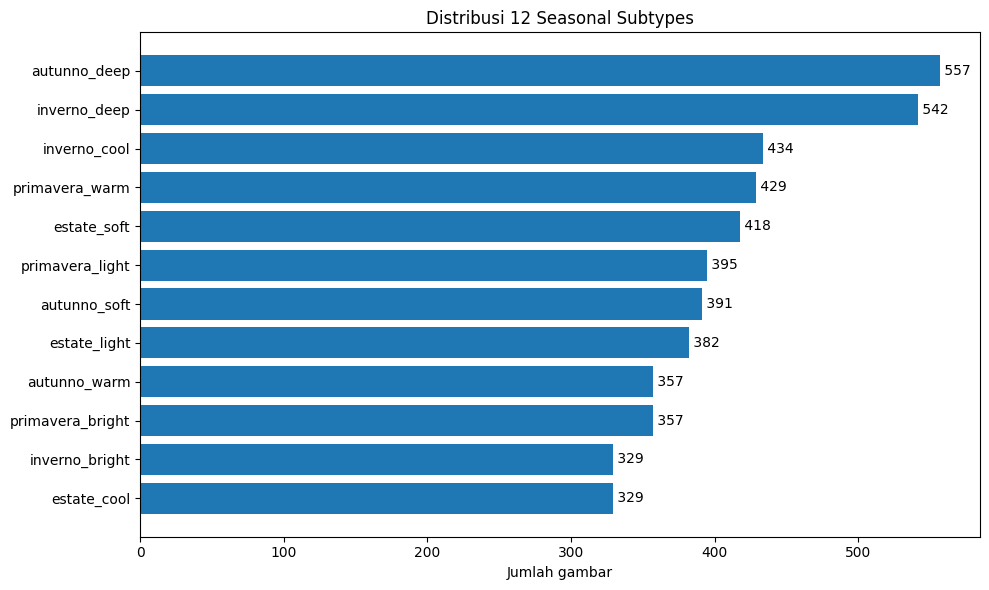

In [9]:
if RUN_FULL_EDA:
    # ============================================================
    # 7. VISUALISASI DISTRIBUSI
    # ============================================================

    fig, ax = plt.subplots(figsize=(10, 6))

    plot_counts = (
        df["joint_label"]
        .value_counts()
        .sort_values()
    )

    ax.barh(plot_counts.index, plot_counts.values)
    ax.set_title("Distribusi 12 Seasonal Subtypes")
    ax.set_xlabel("Jumlah gambar")

    for i, v in enumerate(plot_counts.values):
        ax.text(v, i, f" {v}", va="center")

    plt.tight_layout()
    plt.show()
else:
    print('⏭️ Optional visual EDA dilewati (RUN_FULL_EDA=False).')

In [10]:
# ============================================================
# 8. PATH RESOLVER
# ============================================================

def resolve_image_path(relative_path):
    p = Path(str(relative_path).replace("\\", "/").strip())

    candidates = [
        DATA_ROOT / p,
        DATA_ROOT / "RGB-M" / p,
        DATA_ROOT / "release" / p,
    ]

    # Jika CSV sudah mengandung prefix RGB-M/
    if "RGB-M" in p.parts:
        idx = p.parts.index("RGB-M")
        after_rgbm = Path(*p.parts[idx + 1:])
        candidates.append(DATA_ROOT / "RGB-M" / after_rgbm)

    for candidate in candidates:
        if candidate.exists():
            return candidate

    return None

df["resolved_path"] = df[MASKED_PATH_COL].apply(resolve_image_path)

missing_path_count = int(df["resolved_path"].isna().sum())

print("Total image :", len(df))
print("Path valid  :", len(df) - missing_path_count)
print("Path missing:", missing_path_count)

if missing_path_count:
    print("\nContoh missing path:")
    display(
        df.loc[
            df["resolved_path"].isna(),
            [MASKED_PATH_COL, "joint_label", PARTITION_COL]
        ].head(20)
    )

assert missing_path_count == 0, (
    "Masih ada path missing. Jangan lanjut ke training."
)

print("✅ Seluruh image path valid.")

Total image : 4920
Path valid  : 4920
Path missing: 0
✅ Seluruh image path valid.


In [11]:
# ============================================================
# 9. CORRUPT IMAGE CHECK + IMAGE PROPERTIES
# ============================================================

corrupt_records = []
image_properties = []

for i, row in df.iterrows():
    path = row["resolved_path"]

    try:
        with Image.open(path) as img:
            # Simpan properti terlebih dahulu
            image_properties.append({
                "index": i,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
            })

            # verify() memeriksa integritas file
            img.verify()

    except Exception as e:
        corrupt_records.append({
            "index": i,
            "path": str(path),
            "error": str(e),
        })

corrupt_df = pd.DataFrame(corrupt_records)
image_info_df = pd.DataFrame(image_properties)

print("Corrupt images:", len(corrupt_records))

if len(corrupt_records):
    display(corrupt_df.head(20))

print("\nImage modes:")
display(image_info_df["mode"].value_counts().to_frame("count"))

print("\nResolusi terbanyak:")
display(
    image_info_df
    .value_counts(["width", "height"])
    .head(20)
    .to_frame("count")
)

print("\nStatistik dimensi:")
display(image_info_df[["width", "height"]].describe())

assert len(corrupt_records) == 0, (
    "Ada corrupt image. Perbaiki sebelum training."
)

print("✅ Tidak ada corrupt image.")

Corrupt images: 0

Image modes:


,count
mode,
RGB,4920



Resolusi terbanyak:


,,count
width,height,
512,512,2981
413,489,2
482,618,2
522,376,2
617,674,2
412,542,2
512,479,2
585,731,2
620,848,1



Statistik dimensi:


,width,height
count,4920.000000,4920.000000
mean,534.065650,574.292886
std,211.986499,263.275514
min,45.000000,110.000000
25%,512.000000,512.000000
50%,512.000000,512.000000
75%,512.000000,512.000000
max,2903.000000,3725.000000


✅ Tidak ada corrupt image.


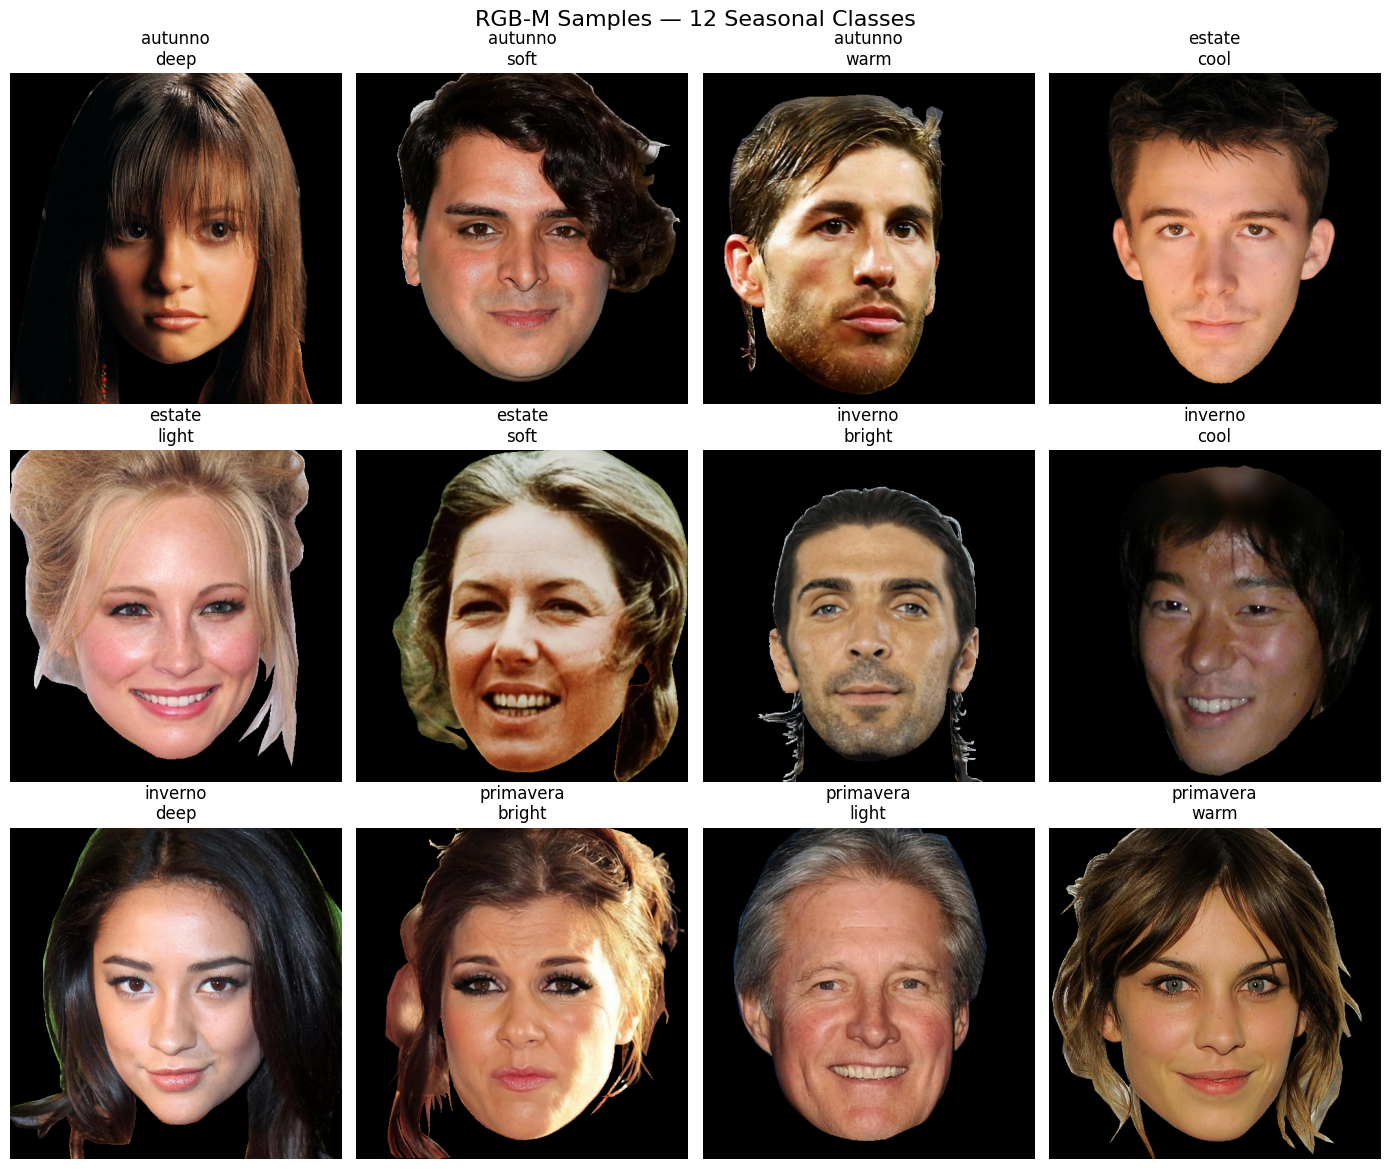

In [12]:
if RUN_FULL_EDA:
    # ============================================================
    # 10. SAMPLE GALLERY — 12 CLASSES
    # ============================================================

    classes = sorted(df["joint_label"].unique())

    fig, axes = plt.subplots(3, 4, figsize=(14, 12))
    axes = axes.flatten()

    for ax, label in zip(axes, classes):
        row = (
            df[df["joint_label"] == label]
            .sample(1, random_state=SEED)
            .iloc[0]
        )

        img = Image.open(row["resolved_path"]).convert("RGB")

        ax.imshow(img)
        ax.set_title(label.replace("_", "\n"))
        ax.axis("off")

    plt.suptitle("RGB-M Samples — 12 Seasonal Classes", fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print('⏭️ Optional visual EDA dilewati (RUN_FULL_EDA=False).')

## 11. Mask-quality audit

Karena kita memakai **RGB-M**, kita perlu memastikan model tidak memperoleh shortcut hanya dari **luas area mask**.

Agar EDA tetap ringan, audit ini mengambil maksimal **50 gambar per class** dan mengecilkannya ke `128×128` hanya untuk analisis statistik.  
Ini **tidak mengubah data training asli**.

visible_ratio                                \
                          mean       std       min       max   
joint_label                                                    
autunno_deep          0.578014  0.164198  0.241516  0.896240   
autunno_soft          0.643208  0.131765  0.451660  0.892639   
autunno_warm          0.639449  0.115843  0.401550  0.895447   
estate_cool           0.665665  0.134486  0.342346  0.892761   
estate_light          0.657821  0.139909  0.260071  0.940186   
estate_soft           0.694133  0.122746  0.391541  0.899292   
inverno_bright        0.600148  0.120058  0.364502  0.859802   
inverno_cool          0.601082  0.119123  0.336243  0.794067   
inverno_deep          0.584603  0.146619  0.220825  0.850464   
primavera_bright      0.667915  0.100472  0.457275  0.861633   
primavera_light       0.680656  0.117018  0.413696  0.933594   
primavera_warm        0.654375  0.126111  0.361328  0.909241   

                 visible_brightness                                    
                               mean        std        min         max  
joint_label                                                            
autunno_deep              86.238530  20.619131  43.190997  126.473491  
autunno_soft             108.343686  18.778161  59.321933  147.913458  
autunno_warm              96.465227  19.682298  56.296324  145.856162  
estate_cool              117.663650  24.469489  75.942565  202.313187  
estate_light             133.601229  20.004244  92.427047  188.350376  
estate_soft              121.745254  24.638709  80.284074  178.355257  
inverno_bright            97.309840  21.326025  64.264628  150.685979  
inverno_cool             101.275164  24.539923  60.722631  190.513886  
inverno_deep              86.778989  19.279685  52.300048  138.537258  
primavera_bright          96.880499  22.320835  49.761870  147.788102  
primavera_light          131.227263  19.792151  97.577874  176.388847  
primavera_warm           109.833254  21.446220  40.774534  144.463393

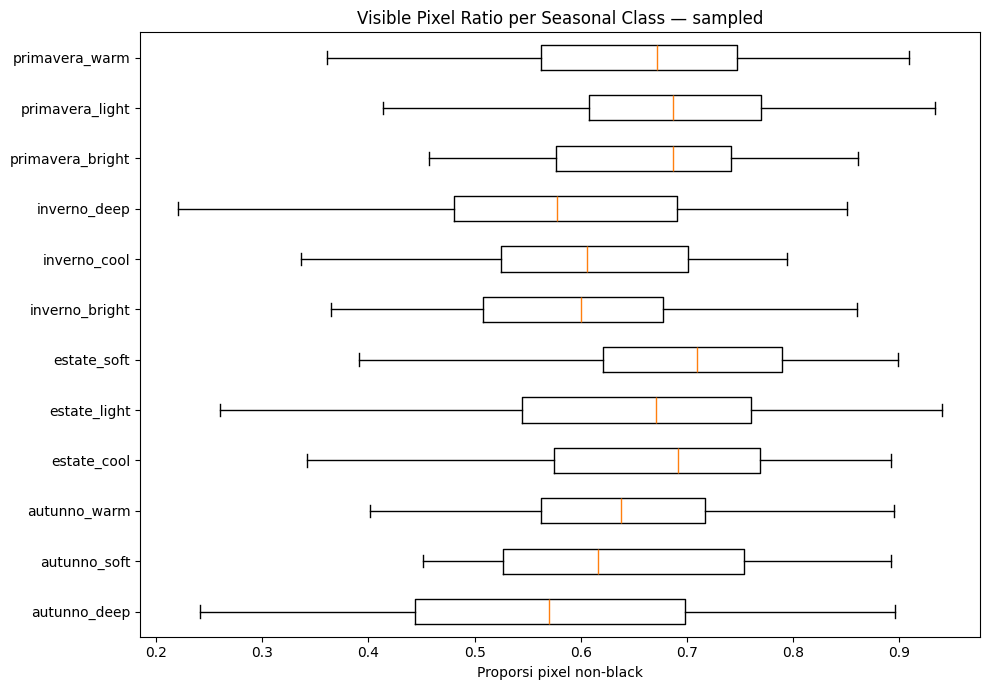

In [13]:
if RUN_MASK_AUDIT:
    # ============================================================
    # 11. SAMPLED MASK / VISIBLE PIXEL RATIO AUDIT
    # ============================================================

    MASK_AUDIT_PER_CLASS = 50
    MASK_AUDIT_SIZE = (128, 128)

    audit_rows = []

    for label in sorted(df["joint_label"].unique()):
        subset = df[df["joint_label"] == label]

        n = min(MASK_AUDIT_PER_CLASS, len(subset))
        sample = subset.sample(n=n, random_state=SEED)

        for _, row in sample.iterrows():
            img = (
                Image.open(row["resolved_path"])
                .convert("RGB")
                .resize(MASK_AUDIT_SIZE)
            )

            arr = np.asarray(img, dtype=np.uint8)

            # Pixel dianggap visible jika setidaknya satu channel > 10
            visible = np.any(arr > 10, axis=2)
            visible_ratio = float(visible.mean())

            visible_pixels = arr[visible]
            brightness = (
                float(visible_pixels.mean())
                if len(visible_pixels) > 0
                else np.nan
            )

            audit_rows.append({
                "joint_label": label,
                "visible_ratio": visible_ratio,
                "visible_brightness": brightness,
            })

    mask_audit_df = pd.DataFrame(audit_rows)

    display(
        mask_audit_df
        .groupby("joint_label")[["visible_ratio", "visible_brightness"]]
        .agg(["mean", "std", "min", "max"])
    )

    classes = sorted(mask_audit_df["joint_label"].unique())
    box_data = [
        mask_audit_df.loc[
            mask_audit_df["joint_label"] == cls,
            "visible_ratio"
        ]
        for cls in classes
    ]

    plt.figure(figsize=(10, 7))
    plt.boxplot(box_data, tick_labels=classes, vert=False)
    plt.title("Visible Pixel Ratio per Seasonal Class — sampled")
    plt.xlabel("Proporsi pixel non-black")
    plt.tight_layout()
    plt.show()
else:
    print('⏭️ Mask audit dilewati (RUN_MASK_AUDIT=False).')

## 12. Duplicate / leakage audit

Pertama kita hitung hash seluruh file.  
Lalu:
1. cek duplicate identik lintas **official train ↔ test**;
2. setelah internal train/validation split dibuat, cek kembali overlap **train ↔ val ↔ test**.

In [14]:
# ============================================================
# 12. FILE HASH AUDIT
# ============================================================

def md5_file(path, chunk_size=1024 * 1024):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

df["md5"] = df["resolved_path"].apply(md5_file)

hash_partition_count = (
    df.groupby("md5")[PARTITION_COL]
    .nunique()
)

cross_official_hashes = hash_partition_count[
    hash_partition_count > 1
]

print(
    "Identical images across official partitions:",
    len(cross_official_hashes)
)

assert len(cross_official_hashes) == 0, (
    "Ada identical image antara official train dan test."
)

print("✅ Official train-test hash leakage: 0.")

Identical images across official partitions: 0
✅ Official train-test hash leakage: 0.


### Perceptual duplicate screening

MD5 hanya menangkap file yang byte-for-byte identik. Sebagai screening tambahan, notebook
menghitung **dHash 64-bit** pada gambar grayscale kecil. Hash yang sama di official train dan test
akan ditampilkan untuk inspeksi.

Ini hanya **screening**; hasil dHash yang sama tidak otomatis dihapus karena perceptual hash dapat
memiliki collision.

In [15]:
if RUN_DHASH_SCREENING:
    # ============================================================
    # COARSE PERCEPTUAL DUPLICATE SCREENING — dHash 64-bit
    # ============================================================

    def dhash64(path):
        img = (
            Image.open(path)
            .convert("L")
            .resize((9, 8))
        )
        arr = np.asarray(img, dtype=np.int16)
        diff = arr[:, 1:] > arr[:, :-1]

        value = 0
        for bit in diff.flatten():
            value = (value << 1) | int(bit)
        return f"{value:016x}"

    df["dhash64"] = df["resolved_path"].apply(dhash64)

    dhash_partition_count = (
        df.groupby("dhash64")[PARTITION_COL]
        .nunique()
    )

    cross_partition_dhashes = (
        dhash_partition_count[
            dhash_partition_count > 1
        ].index
    )

    print(
        "dHash identik yang muncul pada >1 official partition:",
        len(cross_partition_dhashes)
    )

    if len(cross_partition_dhashes) > 0:
        dhash_candidates = df[
            df["dhash64"].isin(cross_partition_dhashes)
        ][
            [
                "dhash64",
                PARTITION_COL,
                "joint_label",
                MASKED_PATH_COL,
                "md5",
            ]
        ].sort_values(["dhash64", PARTITION_COL])

        display(dhash_candidates.head(50))
        print(
            "⚠️ dHash adalah screening, bukan bukti duplicate pasti. "
            "MD5 cross-split tetap menjadi hard leakage check."
        )
    else:
        print("✅ Tidak ada exact dHash yang menyeberang official partition.")
else:
    df['dhash64'] = None
    print('⏭️ dHash screening dilewati (RUN_DHASH_SCREENING=False).')

dHash identik yang muncul pada >1 official partition: 20


,dhash64,partition,joint_label,path_rgb_masked,md5
3095,0000307078783030,test,inverno_cool,RGB-M/test/inverno/cool/718.png,93c063606acca293e96f6a32a4be1fb0
328,0000307078783030,train,autunno_deep,RGB-M/train/autunno/deep/12386.png,edd6e302acbb174b90dcccff6843326b
2347,3070707068687030,test,estate_soft,RGB-M/test/estate/soft/23705.png,62de1b1b6f84b2c3a40bb45c56f3aeb4
118,3070707068687030,train,autunno_deep,RGB-M/train/autunno/deep/12795.png,223967d02134e7d4f6b3ec676cdab9d9
3179,3070707068707030,test,inverno_cool,RGB-M/test/inverno/cool/20138.png,213abf601cd4cbf924641d4c3e8ffe4f
3385,3070707068707030,train,inverno_deep,RGB-M/train/inverno/deep/24009.png,b88b332e109c83aa37ddd097a0101bff
4844,3070f0f0e8e87030,test,primavera_warm,RGB-M/test/primavera/warm/27846.png,a568a2fbcfbbf8dd1d19ba3aad395d98
366,3070f0f0e8e87030,train,autunno_deep,RGB-M/train/autunno/deep/27871.png,4bb6efc0ebf22bb83a8c8239d142048b
3768,3070f0f0e8e87030,train,primavera_bright,RGB-M/train/primavera/bright/25685.png,a6e83d1c7e1da54b97c9d9768887d655
3637,3070f0f0e8f07030,test,inverno_deep,RGB-M/test/inverno/deep/26733.png,7e8a319ab838140b500be1f273a9785e


⚠️ dHash adalah screening, bukan bukti duplicate pasti. MD5 cross-split tetap menjadi hard leakage check.


## 13. Cleaning checkpoint

Cleaning dilakukan **sebelum split internal**.

Karena path dan corrupt check bersifat strict pada notebook ini, semua baris yang sampai ke tahap ini seharusnya valid.  
Kita tetap membuat `clean_df` agar alur penelitian eksplisit.

In [16]:
# ============================================================
# 13. FINAL CLEAN DATAFRAME
# ============================================================

clean_df = df[
    df["resolved_path"].notna()
].copy()

print("Data awal :", len(df))
print("Data clean:", len(clean_df))

clean_joint_counts = clean_df["joint_label"].value_counts()

print("\nDistribusi setelah cleaning:")
display(clean_joint_counts.sort_index().to_frame("count"))

print(
    "\nImbalance ratio setelah cleaning:",
    round(clean_joint_counts.max() / clean_joint_counts.min(), 2)
)

Data awal : 4920
Data clean: 4920

Distribusi setelah cleaning:


,count
joint_label,
autunno_deep,557
autunno_soft,391
autunno_warm,357
estate_cool,329
estate_light,382
estate_soft,418
inverno_bright,329
inverno_cool,434
inverno_deep,542



Imbalance ratio setelah cleaning: 1.69


## 14. Source-aware Train / Validation / Final Test

Official test tetap tidak disentuh.

Karena EDA menunjukkan:
- official test = **100% CelebA**
- official train = campuran CelebA + non-CelebA

maka validation E3 dibuat dari **CelebA official train saja**.

Tujuannya agar checkpoint selection berdasarkan validation lebih dekat dengan domain target
official test, tanpa memakai label official test.

Ukuran validation tetap sama seperti eksperimen sebelumnya: sekitar **602 image**.

In [17]:
# ============================================================
# 14. E3 SOURCE-AWARE SPLIT
# ============================================================

assert VALIDATION_STRATEGY == "celeba_only", (
    "Master notebook saat ini mengimplementasikan VALIDATION_STRATEGY=celeba_only."
)

assert "celeba" in clean_df.columns, (
    "Kolom 'celeba' diperlukan untuk E3 source-aware validation."
)

official_train = clean_df[
    clean_df[PARTITION_COL] == "train"
].copy()

test_df = clean_df[
    clean_df[PARTITION_COL] == "test"
].copy()

# ------------------------------------------------------------
# Audit source official partition
# ------------------------------------------------------------
print("Official train source:")
display(
    official_train["celeba"]
    .value_counts()
    .rename_axis("celeba")
    .to_frame("count")
)

print("\nOfficial test source:")
display(
    test_df["celeba"]
    .value_counts()
    .rename_axis("celeba")
    .to_frame("count")
)

# Official test Deep Armocromia pada dataset ini 100% CelebA
assert bool(test_df["celeba"].all()), (
    "E3 mengharapkan official test 100% CelebA, "
    "tetapi ditemukan non-CelebA pada test."
)

# ------------------------------------------------------------
# Pisahkan source official train
# ------------------------------------------------------------
celeba_pool = official_train[
    official_train["celeba"] == True
].copy()

nonceleba_train = official_train[
    official_train["celeba"] == False
].copy()

print("\nOfficial train CelebA     :", len(celeba_pool))
print("Official train non-CelebA :", len(nonceleba_train))

# Pertahankan ukuran validation eksperimen sebelumnya.
# 15% dari 4008 menghasilkan 602 sample pada sklearn sebelumnya.
VAL_SIZE = math.ceil(
    len(official_train) * VAL_FRACTION_OF_OFFICIAL_TRAIN
)

assert VAL_SIZE < len(celeba_pool), (
    "CelebA pool terlalu kecil untuk validation size."
)

# ------------------------------------------------------------
# Validation 100% CelebA dan stratified 12-class
# ------------------------------------------------------------
celeba_train_part, val_df = train_test_split(
    celeba_pool,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=celeba_pool["joint_label"],
)

# Semua non-CelebA tetap digunakan untuk training
train_df = pd.concat(
    [
        celeba_train_part,
        nonceleba_train,
    ],
    axis=0,
    ignore_index=True,
)

# Shuffle training secara reproducible
train_df = (
    train_df
    .sample(
        frac=1.0,
        random_state=SEED
    )
    .reset_index(drop=True)
)

val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------
print("\nFinal split:")
print("Train :", len(train_df))
print("Val   :", len(val_df))
print("Test  :", len(test_df))

assert len(train_df) + len(val_df) == len(official_train)
assert bool(val_df["celeba"].all()), (
    "Validation E3 harus 100% CelebA."
)
assert bool(test_df["celeba"].all()), (
    "Official test harus 100% CelebA."
)

assert train_df["joint_label"].nunique() == 12
assert val_df["joint_label"].nunique() == 12
assert test_df["joint_label"].nunique() == 12

print("\nTrain distribution:")
display(
    train_df["joint_label"]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

print("\nValidation distribution — CelebA only:")
display(
    val_df["joint_label"]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

print("\nOfficial test distribution:")
display(
    test_df["joint_label"]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

Official train source:


,count
celeba,
True,2069
False,1939



Official test source:


,count
celeba,
True,912



Official train CelebA     : 2069
Official train non-CelebA : 1939

Final split:
Train : 3406
Val   : 602
Test  : 912

Train distribution:


,count
joint_label,
autunno_deep,375
autunno_soft,269
autunno_warm,237
estate_cool,232
estate_light,268
estate_soft,314
inverno_bright,233
inverno_cool,288
inverno_deep,347



Validation distribution — CelebA only:


,count
joint_label,
autunno_deep,70
autunno_soft,49
autunno_warm,46
estate_cool,44
estate_light,44
estate_soft,41
inverno_bright,38
inverno_cool,57
inverno_deep,78



Official test distribution:


,count
joint_label,
autunno_deep,112
autunno_soft,73
autunno_warm,74
estate_cool,53
estate_light,70
estate_soft,63
inverno_bright,58
inverno_cool,89
inverno_deep,117


In [18]:
# ============================================================
# E3 SOURCE DISTRIBUTION AFTER SPLIT
# ============================================================

split_source = pd.DataFrame({
    "train": train_df["celeba"].value_counts(normalize=True),
    "val": val_df["celeba"].value_counts(normalize=True),
    "test": test_df["celeba"].value_counts(normalize=True),
}).fillna(0) * 100

print("Persentase source per final split:")
display(split_source.round(2))

print("\nTarget E3:")
print("- Train : CelebA + non-CelebA")
print("- Val   : 100% CelebA")
print("- Test  : 100% CelebA")

assert round(
    float(val_df["celeba"].mean()),
    6
) == 1.0

assert round(
    float(test_df["celeba"].mean()),
    6
) == 1.0

print("✅ Source-aware split PASS.")

Persentase source per final split:


,train,val,test
celeba,,,
False,56.93,0.0,0.0
True,43.07,100.0,100.0



Target E3:
- Train : CelebA + non-CelebA
- Val   : 100% CelebA
- Test  : 100% CelebA
✅ Source-aware split PASS.


### Distribusi kelas Validation vs Official Test

Validation sama-sama 100% CelebA seperti official test, tetapi tetap berasal dari official train.
Cell ini membandingkan proporsi 12 kelas agar kita dapat melihat seberapa representatif holdout E3.

In [19]:
# ============================================================
# CLASS DISTRIBUTION ALIGNMENT — VAL VS OFFICIAL TEST
# ============================================================

val_pct = (
    val_df["joint_label"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

test_pct = (
    test_df["joint_label"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

alignment_df = pd.DataFrame({
    "val_pct": val_pct,
    "test_pct": test_pct,
}).fillna(0)

alignment_df["abs_gap_pp"] = (
    alignment_df["val_pct"]
    - alignment_df["test_pct"]
).abs()

display(
    alignment_df.round(2)
)

print(
    "Mean absolute class-proportion gap:",
    f"{alignment_df['abs_gap_pp'].mean():.2f} percentage points"
)

,val_pct,test_pct,abs_gap_pp
joint_label,,,
autunno_deep,11.63,12.28,0.65
autunno_soft,8.14,8.00,0.14
autunno_warm,7.64,8.11,0.47
estate_cool,7.31,5.81,1.50
estate_light,7.31,7.68,0.37
estate_soft,6.81,6.91,0.10
inverno_bright,6.31,6.36,0.05
inverno_cool,9.47,9.76,0.29
inverno_deep,12.96,12.83,0.13


Mean absolute class-proportion gap: 0.39 percentage points


In [20]:
# ============================================================
# 15. FINAL TRAIN / VAL / TEST HASH LEAKAGE CHECK
# ============================================================

train_hashes = set(train_df["md5"])
val_hashes = set(val_df["md5"])
test_hashes = set(test_df["md5"])

train_val_overlap = len(train_hashes & val_hashes)
train_test_overlap = len(train_hashes & test_hashes)
val_test_overlap = len(val_hashes & test_hashes)

print("Train-Val overlap :", train_val_overlap)
print("Train-Test overlap:", train_test_overlap)
print("Val-Test overlap  :", val_test_overlap)

assert train_val_overlap == 0, "Leakage train-val ditemukan."
assert train_test_overlap == 0, "Leakage train-test ditemukan."
assert val_test_overlap == 0, "Leakage val-test ditemukan."

print("✅ Semua split bebas identical-file leakage.")

Train-Val overlap : 0
Train-Test overlap: 0
Val-Test overlap  : 0
✅ Semua split bebas identical-file leakage.


In [21]:
# ============================================================
# 16. ENCODE 12 JOINT CLASSES
# ============================================================

class_names = sorted(train_df["joint_label"].unique())

assert len(class_names) == 12, (
    f"Expected 12 classes, ditemukan {len(class_names)}."
)

class2idx = {
    name: idx
    for idx, name in enumerate(class_names)
}

idx2class = {
    idx: name
    for name, idx in class2idx.items()
}

print("Class mapping:")
for name, idx in class2idx.items():
    print(f"{idx:2d} -> {name}")

Class mapping:
 0 -> autunno_deep
 1 -> autunno_soft
 2 -> autunno_warm
 3 -> estate_cool
 4 -> estate_light
 5 -> estate_soft
 6 -> inverno_bright
 7 -> inverno_cool
 8 -> inverno_deep
 9 -> primavera_bright
10 -> primavera_light
11 -> primavera_warm


## 17. Preprocessing RGB-M

Karena resolusi gambar bervariasi, kita **tidak langsung memaksa aspect ratio menjadi 224×224**.

Pipeline:
1. `PadToSquare(fill=0)` → mempertahankan aspect ratio dan memakai background hitam yang konsisten dengan RGB-M.
2. Resize → `224×224`.
3. Train-only augmentation:
   - horizontal flip;
   - rotation kecil ±7° dengan `fill=0`.
4. ImageNet normalization.

Tidak digunakan:
- hue jitter;
- saturation jitter;
- grayscale;
- invert;
- augmentasi warna agresif.

In [22]:
# ============================================================
# 17. PREPROCESSING / TRANSFORMS
# ============================================================

import torch
from torchvision import transforms
from torchvision.transforms import functional as TF

IMG_SIZE = 224
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

# Default dibuat FAIR terhadap baseline:
# foreground crop dan color jitter tersedia tetapi OFF.
# Aktifkan pada eksperimen berikutnya agar efeknya bisa diukur terpisah.


class CropVisibleForeground:
    """
    Crop bounding box pixel non-black pada RGB-M + margin.
    Dikontrol dari MASTER EXPERIMENT CONFIG.
    """
    def __init__(self, threshold=10, margin=0.08):
        self.threshold = threshold
        self.margin = margin

    def __call__(self, image):
        arr = np.asarray(image.convert("RGB"))
        mask = np.any(arr > self.threshold, axis=2)

        ys, xs = np.where(mask)
        if len(xs) == 0 or len(ys) == 0:
            return image

        x0, x1 = xs.min(), xs.max()
        y0, y1 = ys.min(), ys.max()

        w = x1 - x0 + 1
        h = y1 - y0 + 1

        mx = int(round(w * self.margin))
        my = int(round(h * self.margin))

        x0 = max(0, x0 - mx)
        y0 = max(0, y0 - my)
        x1 = min(image.width - 1, x1 + mx)
        y1 = min(image.height - 1, y1 + my)

        return image.crop((x0, y0, x1 + 1, y1 + 1))


class PadToSquare:
    def __init__(self, fill=0):
        self.fill = fill

    def __call__(self, image):
        w, h = image.size
        max_side = max(w, h)

        pad_left = (max_side - w) // 2
        pad_right = max_side - w - pad_left
        pad_top = (max_side - h) // 2
        pad_bottom = max_side - h - pad_top

        return TF.pad(
            image,
            padding=[
                pad_left,
                pad_top,
                pad_right,
                pad_bottom,
            ],
            fill=self.fill,
        )


train_ops = []

if USE_FOREGROUND_CROP:
    train_ops.append(
        CropVisibleForeground(
            threshold=10,
            margin=0.08
        )
    )

train_ops.extend([
    PadToSquare(fill=0),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=7,
        fill=0,
    ),
])

if USE_MILD_COLOR_AUG:
    train_ops.append(
        transforms.ColorJitter(
            brightness=0.08,
            contrast=0.08,
            saturation=0.04,
            hue=0.0,
        )
    )

train_ops.extend([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=NORM_MEAN,
        std=NORM_STD,
    ),
])

eval_ops = []

if USE_FOREGROUND_CROP:
    eval_ops.append(
        CropVisibleForeground(
            threshold=10,
            margin=0.08
        )
    )

eval_ops.extend([
    PadToSquare(fill=0),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=NORM_MEAN,
        std=NORM_STD,
    ),
])

train_transform = transforms.Compose(train_ops)
eval_transform = transforms.Compose(eval_ops)

print("✅ Transform siap.")
print("Foreground crop :", USE_FOREGROUND_CROP)
print("Mild color aug  :", USE_MILD_COLOR_AUG)

✅ Transform siap.
Foreground crop : False
Mild color aug  : False


In [23]:
# ============================================================
# 18. PYTORCH DATASET
# ============================================================

from torch.utils.data import Dataset

class ArmocromiaDataset(Dataset):
    def __init__(
        self,
        dataframe,
        class2idx,
        transform=None,
    ):
        self.df = dataframe.reset_index(drop=True)
        self.class2idx = class2idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(
            row["resolved_path"]
        ).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = self.class2idx[
            row["joint_label"]
        ]

        return (
            image,
            torch.tensor(label, dtype=torch.long),
        )

train_dataset = ArmocromiaDataset(
    train_df,
    class2idx,
    train_transform,
)

val_dataset = ArmocromiaDataset(
    val_df,
    class2idx,
    eval_transform,
)

test_dataset = ArmocromiaDataset(
    test_df,
    class2idx,
    eval_transform,
)

print("Train dataset:", len(train_dataset))
print("Val dataset  :", len(val_dataset))
print("Test dataset :", len(test_dataset))

Train dataset: 3406
Val dataset  : 602
Test dataset : 912


In [24]:
# ============================================================
# 19. DATALOADER
# ============================================================

from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = min(4, os.cpu_count() or 2)
PIN_MEMORY = torch.cuda.is_available()

# Reproducible shuffle
generator = torch.Generator()
generator.manual_seed(SEED)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

common_loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
)

if NUM_WORKERS > 0:
    common_loader_kwargs["persistent_workers"] = True
    common_loader_kwargs["prefetch_factor"] = 2

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    generator=generator,
    **common_loader_kwargs,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **common_loader_kwargs,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **common_loader_kwargs,
)

print("Batch size   :", BATCH_SIZE)
print("Workers      :", NUM_WORKERS)
print("Pin memory   :", PIN_MEMORY)
print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

Batch size   : 32
Workers      : 4
Pin memory   : True
Train batches: 107
Val batches  : 19
Test batches : 29


In [25]:
# ============================================================
# 20. BATCH SANITY CHECK
# ============================================================

images, labels = next(iter(train_loader))

print("Image batch :", images.shape)
print("Label batch :", labels.shape)
print("Image dtype :", images.dtype)
print("Label dtype :", labels.dtype)
print("Label min   :", labels.min().item())
print("Label max   :", labels.max().item())

assert images.ndim == 4
assert images.shape[1:] == (3, IMG_SIZE, IMG_SIZE)
assert labels.min().item() >= 0
assert labels.max().item() <= 11

print("✅ Batch tensor sanity check PASS.")

Image batch : torch.Size([32, 3, 224, 224])
Label batch : torch.Size([32])
Image dtype : torch.float32
Label dtype : torch.int64
Label min   : 0
Label max   : 11
✅ Batch tensor sanity check PASS.


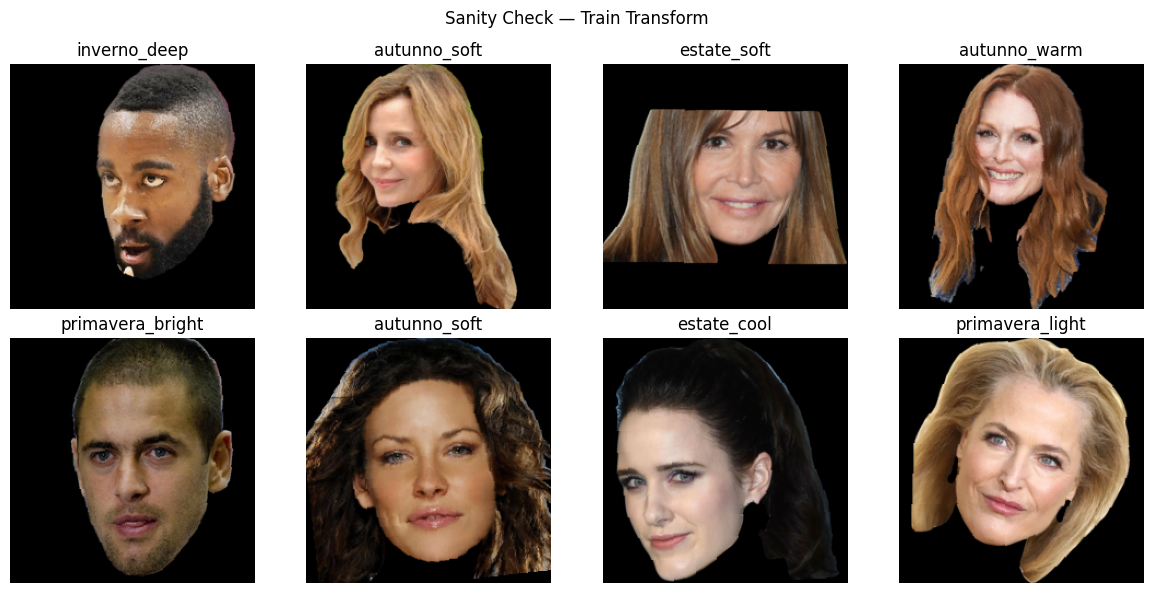

In [26]:
if RUN_FULL_EDA:
    # ============================================================
    # 21. VISUAL SANITY CHECK AFTER PREPROCESSING
    # ============================================================

    def denormalize(img):
        mean = torch.tensor(NORM_MEAN).view(3, 1, 1)
        std = torch.tensor(NORM_STD).view(3, 1, 1)
        return img * std + mean

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(12, 6),
    )

    for i, ax in enumerate(axes.flat):
        img = denormalize(
            images[i].cpu()
        ).clamp(0, 1)

        ax.imshow(
            img.permute(1, 2, 0)
        )

        ax.set_title(
            idx2class[
                labels[i].item()
            ]
        )
        ax.axis("off")

    plt.suptitle("Sanity Check — Train Transform")
    plt.tight_layout()
    plt.show()
else:
    print('⏭️ Optional visual EDA dilewati (RUN_FULL_EDA=False).')

## 22. Simpan manifest split & mapping

Manifest ini kecil dan berguna untuk:
- reproduksi eksperimen;
- dokumentasi laporan;
- memastikan training session berikutnya menggunakan split yang sama.

File gambar **tidak disalin ulang** pada tahap ini.

In [27]:
# ============================================================
# 22. SAVE SPLIT MANIFESTS & CLASS MAPPING
# ============================================================

ARTIFACT_DIR = Path("/kaggle/working/pretraining_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

manifest_cols = [
    SEASON_COL,
    SUBCLASS_COL,
    "joint_label",
    PARTITION_COL,
    MASKED_PATH_COL,
    "md5",
]

train_df[manifest_cols].to_csv(
    ARTIFACT_DIR / "train_split.csv",
    index=False,
)

val_df[manifest_cols].to_csv(
    ARTIFACT_DIR / "val_split.csv",
    index=False,
)

test_df[manifest_cols].to_csv(
    ARTIFACT_DIR / "test_split.csv",
    index=False,
)

with open(
    ARTIFACT_DIR / "class_mapping.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {
            "class2idx": class2idx,
            "idx2class": {
                str(k): v
                for k, v in idx2class.items()
            },
            "seed": SEED,
            "img_size": IMG_SIZE,
            "batch_size": BATCH_SIZE,
        },
        f,
        indent=2,
    )

print("Saved to:", ARTIFACT_DIR)
for p in sorted(ARTIFACT_DIR.iterdir()):
    print("-", p.name)

Saved to: /kaggle/working/pretraining_artifacts
- class_mapping.json
- test_split.csv
- train_split.csv
- val_split.csv


In [28]:
# ============================================================
# 23. FINAL READINESS SUMMARY
# ============================================================

summary = {
    "mode": MODE,
    "total_annotation": len(df),
    "valid_paths": int(df["resolved_path"].notna().sum()),
    "corrupt_images": len(corrupt_records),
    "season_classes": int(df[SEASON_COL].nunique()),
    "joint_classes": int(df["joint_label"].nunique()),
    "official_train": int((df[PARTITION_COL] == "train").sum()),
    "official_test": int((df[PARTITION_COL] == "test").sum()),
    "internal_train": len(train_df),
    "internal_val": len(val_df),
    "final_test": len(test_df),
    "official_cross_split_duplicate_hashes": len(cross_official_hashes),
    "train_val_overlap": train_val_overlap,
    "train_test_overlap": train_test_overlap,
    "val_test_overlap": val_test_overlap,
    "imbalance_ratio": round(
        float(clean_joint_counts.max() / clean_joint_counts.min()),
        3,
    ),
    "batch_shape": list(images.shape),
    "validation_celeba_percent": round(float(val_df["celeba"].mean()) * 100, 2),
    "test_celeba_percent": round(float(test_df["celeba"].mean()) * 100, 2),
}

display(
    pd.DataFrame(
        summary.items(),
        columns=["Metric", "Value"],
    )
)

checks = {
    "4920 image path valid": int(df["resolved_path"].notna().sum()) == len(df),
    "0 corrupt image": len(corrupt_records) == 0,
    "4 season": df[SEASON_COL].nunique() == 4,
    "12 joint classes": df["joint_label"].nunique() == 12,
    "0 official train-test identical-file leakage": len(cross_official_hashes) == 0,
    "0 train-val leakage": train_val_overlap == 0,
    "0 train-test leakage": train_test_overlap == 0,
    "0 val-test leakage": val_test_overlap == 0,
    "Batch = [B, 3, 224, 224]": tuple(images.shape[1:]) == (3, 224, 224),
    "Label range = 0..11": labels.min().item() >= 0 and labels.max().item() <= 11,
    "Validation 100% CelebA": bool(val_df["celeba"].all()),
    "Official test 100% CelebA": bool(test_df["celeba"].all()),
}

all_passed = True

print("\n" + "=" * 72)
print("PRE-TRAINING READINESS")
print("=" * 72)

for name, passed in checks.items():
    status = "PASS" if passed else "FAIL"
    print(f"[{status}] {name}")
    all_passed &= bool(passed)

print("=" * 72)

if all_passed:
    print("✅ DATASET + PREPROCESSING READY FOR EFFICIENTNET TRAINING")
    print("STOP DI SINI. Training model dibuat pada session/notebook berikutnya.")
else:
    print("❌ BELUM READY. Perbaiki semua check yang FAIL sebelum training.")

,Metric,Value
0,mode,ENCRYPTED_SOURCE
1,total_annotation,4920
2,valid_paths,4920
3,corrupt_images,0
4,season_classes,4
5,joint_classes,12
6,official_train,4008
7,official_test,912
8,internal_train,3406
9,internal_val,602



PRE-TRAINING READINESS
[PASS] 4920 image path valid
[PASS] 0 corrupt image
[PASS] 4 season
[PASS] 12 joint classes
[PASS] 0 official train-test identical-file leakage
[PASS] 0 train-val leakage
[PASS] 0 train-test leakage
[PASS] 0 val-test leakage
[PASS] Batch = [B, 3, 224, 224]
[PASS] Label range = 0..11
[PASS] Validation 100% CelebA
[PASS] Official test 100% CelebA
✅ DATASET + PREPROCESSING READY FOR EFFICIENTNET TRAINING
STOP DI SINI. Training model dibuat pada session/notebook berikutnya.


## Recipe untuk Version berikutnya

### E4 — Foreground Crop
Pertahankan parameter E3, lalu ubah:

```python
EXPERIMENT_ID = "E4"
EXPERIMENT_NAME = "Foreground Crop + Source-Aware Validation"
USE_FOREGROUND_CROP = True
USE_MILD_COLOR_AUG = False
```

Tujuan: mengurangi kemungkinan model memakai luas/background mask sebagai shortcut.

### E5 — Mild Color Augmentation
Setelah E4 selesai, ubah:

```python
EXPERIMENT_ID = "E5"
EXPERIMENT_NAME = "Mild Color Augmentation"
USE_MILD_COLOR_AUG = True
```

Gunakan setting crop berdasarkan hasil E4 supaya keputusan tetap berbasis eksperimen.

### E6 — Hierarchical Learning
E6 membutuhkan perubahan arsitektur:
- main head = 12 class
- auxiliary head = 4 season

Jadi E6 bukan sekadar mengubah flag config.

# Training — Controlled Experiment from MASTER CONFIG

E3 mencoba titik tengah antara dua eksperimen sebelumnya.

## Baseline E0
- full fine-tuning
- official test Accuracy: **30.59%**
- overfitting kuat

## E1+E2
- last 3 blocks trainable
- 2-layer classifier
- official test Accuracy: **26.86%**
- generalization memburuk karena backbone terlalu dibatasi

## E3
- **validation = 100% CelebA**
- **last 5 feature blocks trainable**
- classifier `1280 → 640 → ReLU → Dropout(0.40) → 12`
- backbone LR = `3e-5`
- classifier LR = `2e-4`
- checkpoint dipilih dari **CelebA validation Macro F1**

Preprocessing utama tetap sama dengan E0/E1+E2 supaya efek E3 dapat diukur secara fair.
Foreground crop dan color augmentation tetap OFF pada eksperimen ini.

## 24. GPU / environment check

Untuk training:
- Kaggle Settings → Accelerator → **GPU T4**
- pastikan `torch.cuda.is_available()` bernilai `True`.

Jika `False`, **jangan training** karena proses akan jatuh ke CPU dan jauh lebih lambat.

In [29]:
# ============================================================
# 24. DEVICE / CUDA CHECK
# ============================================================

import torch
import torchvision

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Device      :", DEVICE)

if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))
    print(
        "VRAM total  :",
        round(
            torch.cuda.get_device_properties(0).total_memory / (1024**3),
            2
        ),
        "GiB"
    )

assert DEVICE.type == "cuda", (
    "GPU belum aktif. Kaggle Settings -> Accelerator -> GPU T4, "
    "lalu restart/run kembali."
)

PyTorch     : 2.11.0+cu128
Torchvision : 0.26.0+cu128
Device      : cuda
GPU         : Tesla T4
VRAM total  : 14.56 GiB


## 25. EfficientNet-B0 baseline

Stage 1 melatih classifier head dengan backbone dibekukan sebentar.  
Stage 2 membuka seluruh backbone dan melakukan fine-tuning dengan learning rate lebih kecil.

In [30]:
# ============================================================
# 25. BUILD E3 EFFICIENTNET-B0
# ============================================================

import torch.nn as nn
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights,
)

NUM_CLASSES = len(class_names)

weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(
    weights=weights
)

# Stage 1: freeze seluruh EfficientNet features
for param in model.features.parameters():
    param.requires_grad = False

in_features = model.classifier[1].in_features
hidden_features = in_features // 2

model.classifier = nn.Sequential(
    nn.Linear(
        in_features,
        hidden_features
    ),
    nn.ReLU(inplace=True),
    nn.Dropout(p=DROPOUT),
    nn.Linear(
        hidden_features,
        NUM_CLASSES
    ),
)

model = model.to(DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_stage1 = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Experiment       :", EXPERIMENT_ID, "-", EXPERIMENT_NAME)
print("Classes          :", NUM_CLASSES)
print("Feature dim      :", in_features)
print("Hidden dim       :", hidden_features)
print("Dropout          :", DROPOUT)
print("Total params     :", f"{total_params:,}")
print("Trainable stage1 :", f"{trainable_stage1:,}")

print("\nClassifier:")
print(model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s]


Experiment       : E3 - Source-Aware CelebA Validation + 5-Block Fine-Tuning
Classes          : 12
Feature dim      : 1280
Hidden dim       : 640
Dropout          : 0.4
Total params     : 4,835,080
Trainable stage1 : 827,532

Classifier:
Sequential(
  (0): Linear(in_features=1280, out_features=640, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.4, inplace=False)
  (3): Linear(in_features=640, out_features=12, bias=True)
)


In [31]:
# ============================================================
# 26. ONE-BATCH GPU FORWARD SANITY CHECK
# ============================================================

model.eval()

sample_images, sample_labels = next(
    iter(train_loader)
)

sample_images = sample_images.to(
    DEVICE,
    non_blocking=True
)

with torch.no_grad():
    sample_logits = model(
        sample_images
    )

print("Input :", sample_images.shape)
print("Output:", sample_logits.shape)

assert sample_logits.shape == (
    sample_images.shape[0],
    NUM_CLASSES,
)

print("✅ GPU forward pass PASS.")

Input : torch.Size([32, 3, 224, 224])
Output: torch.Size([32, 12])
✅ GPU forward pass PASS.


## 27. Training utilities

Best model dipilih berdasarkan **validation Macro F1**, bukan hanya accuracy.  
Hal ini lebih sesuai karena kita ingin performa antarkelas tetap seimbang.

In [32]:
# ============================================================
# 27. METRICS + TRAIN / EVAL FUNCTIONS
# ============================================================

import time
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)

criterion = nn.CrossEntropyLoss()

USE_AMP = DEVICE.type == "cuda"

try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )
except Exception:
    scaler = torch.cuda.amp.GradScaler(
        enabled=USE_AMP
    )


def autocast_context():
    if USE_AMP:
        try:
            return torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            )
        except Exception:
            return torch.cuda.amp.autocast()

    from contextlib import nullcontext
    return nullcontext()


def classification_metrics(
    y_true,
    y_pred
):
    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )
    )

    _, _, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0,
        )
    )

    return {
        "accuracy": float(accuracy),
        "macro_precision": float(macro_precision),
        "macro_recall": float(macro_recall),
        "macro_f1": float(macro_f1),
        "weighted_f1": float(weighted_f1),
    }


def set_frozen_feature_blocks_eval(
    model,
    unfrozen_last_n=0
):
    """
    Frozen parameter tidak berubah oleh optimizer, tetapi BatchNorm
    running_mean/running_var masih bisa berubah saat model.train().
    Karena itu block yang frozen dipaksa eval().
    """
    n_blocks = len(model.features)

    if unfrozen_last_n <= 0:
        frozen_blocks = model.features
    else:
        frozen_until = max(
            0,
            n_blocks - unfrozen_last_n
        )
        frozen_blocks = model.features[:frozen_until]

    for block in frozen_blocks:
        block.eval()


def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    unfrozen_last_n=0,
    grad_clip=1.0,
):
    model.train()
    set_frozen_feature_blocks_eval(
        model,
        unfrozen_last_n=unfrozen_last_n
    )

    running_loss = 0.0
    y_true = []
    y_pred = []

    for images_batch, labels_batch in loader:
        images_batch = images_batch.to(
            DEVICE,
            non_blocking=True,
        )
        labels_batch = labels_batch.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with autocast_context():
            logits = model(images_batch)
            loss = criterion(
                logits,
                labels_batch
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            [
                p for p in model.parameters()
                if p.requires_grad
            ],
            max_norm=grad_clip,
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += (
            loss.item()
            * images_batch.size(0)
        )

        preds = logits.argmax(dim=1)

        y_true.extend(
            labels_batch.detach().cpu().tolist()
        )
        y_pred.extend(
            preds.detach().cpu().tolist()
        )

    metrics = classification_metrics(
        y_true,
        y_pred
    )

    metrics["loss"] = (
        running_loss
        / len(loader.dataset)
    )

    return metrics


@torch.no_grad()
def evaluate_loader(
    model,
    loader,
    criterion,
    return_probs=False,
):
    model.eval()

    running_loss = 0.0
    y_true = []
    y_pred = []
    prob_list = []

    for images_batch, labels_batch in loader:
        images_batch = images_batch.to(
            DEVICE,
            non_blocking=True,
        )
        labels_batch = labels_batch.to(
            DEVICE,
            non_blocking=True,
        )

        with autocast_context():
            logits = model(images_batch)
            loss = criterion(
                logits,
                labels_batch
            )

        probs = torch.softmax(
            logits,
            dim=1
        )

        preds = probs.argmax(dim=1)

        running_loss += (
            loss.item()
            * images_batch.size(0)
        )

        y_true.extend(
            labels_batch.cpu().tolist()
        )
        y_pred.extend(
            preds.cpu().tolist()
        )

        if return_probs:
            prob_list.append(
                probs.cpu()
            )

    metrics = classification_metrics(
        y_true,
        y_pred
    )
    metrics["loss"] = (
        running_loss
        / len(loader.dataset)
    )

    if return_probs:
        probs_all = torch.cat(
            prob_list,
            dim=0
        ).numpy()

        top3_idx = np.argsort(
            probs_all,
            axis=1
        )[:, -3:]

        top3 = float(
            np.mean([
                true in row
                for true, row in zip(
                    y_true,
                    top3_idx
                )
            ])
        )

        metrics["top3_accuracy"] = top3

        return (
            metrics,
            np.array(y_true),
            np.array(y_pred),
            probs_all,
        )

    return metrics

## 28. Stage 1 — train classifier head

Backbone dibekukan selama 3 epoch. Ini memberi classifier kesempatan menyesuaikan diri dengan 12 kelas baru tanpa langsung mengubah feature extractor pretrained.

In [33]:
# ============================================================
# 28. E3 STAGE 1 — CLASSIFIER HEAD
# ============================================================





optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=HEAD_LR,
    weight_decay=WEIGHT_DECAY,
)

history = []

print(f"{EXPERIMENT_ID} STAGE 1 — classifier head")
print("=" * 100)

for epoch in range(
    1,
    STAGE1_EPOCHS + 1
):
    start = time.time()

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        unfrozen_last_n=0,
    )

    val_metrics = evaluate_loader(
        model,
        val_loader,
        criterion,
    )

    elapsed = time.time() - start

    row = {
        "stage": 1,
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["accuracy"],
        "train_macro_recall": train_metrics["macro_recall"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["accuracy"],
        "val_macro_recall": val_metrics["macro_recall"],
        "val_macro_f1": val_metrics["macro_f1"],
        "seconds": elapsed,
    }

    history.append(row)

    print(
        f"Epoch {epoch:02d}/{STAGE1_EPOCHS} | "
        f"{elapsed:6.1f}s | "
        f"train loss {train_metrics['loss']:.4f} "
        f"acc {train_metrics['accuracy']:.4f} "
        f"F1 {train_metrics['macro_f1']:.4f} | "
        f"CELEBA val loss {val_metrics['loss']:.4f} "
        f"acc {val_metrics['accuracy']:.4f} "
        f"recall {val_metrics['macro_recall']:.4f} "
        f"F1 {val_metrics['macro_f1']:.4f}"
    )

E3 STAGE 1 — classifier head
Epoch 01/4 |   34.2s | train loss 2.1899 acc 0.2234 F1 0.1972 | CELEBA val loss 2.1404 acc 0.2110 recall 0.1770 F1 0.1261
Epoch 02/4 |   21.8s | train loss 1.9317 acc 0.3062 F1 0.2846 | CELEBA val loss 2.1068 acc 0.2292 recall 0.2002 F1 0.1725
Epoch 03/4 |   22.1s | train loss 1.8310 acc 0.3426 F1 0.3245 | CELEBA val loss 2.0887 acc 0.2591 recall 0.2283 F1 0.1991
Epoch 04/4 |   22.1s | train loss 1.7568 acc 0.3852 F1 0.3693 | CELEBA val loss 2.1174 acc 0.2409 recall 0.2083 F1 0.1919


## 29. E3 Stage 2 — Five-block Fine-Tuning

E3 membuka **5 feature blocks terakhir**.

Ini adalah middle-ground:
- E0: seluruh backbone → terlalu overfit
- E1+E2: 3 block → terlalu restrictive
- E3: **5 block**

Hyperparameter:
- Backbone LR = `3e-5`
- Classifier LR = `2e-4`
- ReduceLROnPlateau
- Early stopping patience = 6
- Selection metric = **CelebA validation Macro F1**

In [34]:
# ============================================================
# 29. E3 STAGE 2 — PARTIAL FINE-TUNING (LAST 5 BLOCKS)
# ============================================================



# Freeze semua features terlebih dahulu
for param in model.features.parameters():
    param.requires_grad = False

# Buka hanya 5 feature blocks terakhir
for block in model.features[-UNFREEZE_LAST_N_BLOCKS:]:
    for param in block.parameters():
        param.requires_grad = True






optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p for p in model.features.parameters()
                if p.requires_grad
            ],
            "lr": BACKBONE_LR,
        },
        {
            "params": model.classifier.parameters(),
            "lr": CLASSIFIER_LR,
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
)

BEST_MODEL_PATH = Path(
    f"/kaggle/working/{EXPERIMENT_ID}_best_efficientnet_b0_rgbm.pth"
)

best_val_f1 = -1.0
best_epoch = None
epochs_without_improvement = 0

trainable_stage2 = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"{EXPERIMENT_ID} STAGE 2 — partial fine-tuning")
print("Validation domain    : 100% CelebA")
print("Unfreeze last blocks :", UNFREEZE_LAST_N_BLOCKS)
print("Trainable params     :", f"{trainable_stage2:,}")
print("Backbone LR          :", BACKBONE_LR)
print("Classifier LR        :", CLASSIFIER_LR)
print("=" * 110)

for epoch in range(
    1,
    MAX_FINETUNE_EPOCHS + 1
):
    start = time.time()

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        unfrozen_last_n=UNFREEZE_LAST_N_BLOCKS,
    )

    val_metrics = evaluate_loader(
        model,
        val_loader,
        criterion,
    )

    scheduler.step(
        val_metrics["macro_f1"]
    )

    elapsed = time.time() - start
    global_epoch = STAGE1_EPOCHS + epoch

    row = {
        "stage": 2,
        "epoch": global_epoch,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["accuracy"],
        "train_macro_recall": train_metrics["macro_recall"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["accuracy"],
        "val_macro_recall": val_metrics["macro_recall"],
        "val_macro_f1": val_metrics["macro_f1"],
        "seconds": elapsed,
        "backbone_lr": optimizer.param_groups[0]["lr"],
        "classifier_lr": optimizer.param_groups[1]["lr"],
    }

    history.append(row)

    improved = (
        val_metrics["macro_f1"]
        > best_val_f1 + 1e-4
    )

    if improved:
        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = global_epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class2idx": class2idx,
                "idx2class": idx2class,
                "best_epoch": best_epoch,
                "best_val_macro_f1": best_val_f1,
                "img_size": IMG_SIZE,
                "norm_mean": NORM_MEAN,
                "norm_std": NORM_STD,
                "seed": SEED,
                "experiment": EXPERIMENT_ID,
                    "experiment_name": EXPERIMENT_NAME,
                    "hypothesis": EXPERIMENT_HYPOTHESIS,
                "validation_source": "celeba_only_from_official_train",
                "unfreeze_last_n_blocks": UNFREEZE_LAST_N_BLOCKS,
                "use_foreground_crop": USE_FOREGROUND_CROP,
                "use_mild_color_aug": USE_MILD_COLOR_AUG,
            },
            BEST_MODEL_PATH,
        )

        marker = "✅ BEST"

    else:
        epochs_without_improvement += 1
        marker = ""

    print(
        f"Epoch {global_epoch:02d} | "
        f"{elapsed:6.1f}s | "
        f"train loss {train_metrics['loss']:.4f} "
        f"acc {train_metrics['accuracy']:.4f} "
        f"F1 {train_metrics['macro_f1']:.4f} | "
        f"CELEBA val loss {val_metrics['loss']:.4f} "
        f"acc {val_metrics['accuracy']:.4f} "
        f"recall {val_metrics['macro_recall']:.4f} "
        f"F1 {val_metrics['macro_f1']:.4f} | "
        f"LR {optimizer.param_groups[0]['lr']:.2e}/"
        f"{optimizer.param_groups[1]['lr']:.2e} "
        f"{marker}"
    )

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):
        print(
            f"\nEarly stopping: tidak ada peningkatan "
            f"CelebA validation Macro F1 selama "
            f"{EARLY_STOPPING_PATIENCE} epoch."
        )
        break

print("\nBest epoch             :", best_epoch)
print("Best CelebA Val F1     :", round(best_val_f1, 4))
print("Best model             :", BEST_MODEL_PATH)

E3 STAGE 2 — partial fine-tuning
Validation domain    : 100% CelebA
Unfreeze last blocks : 5
Trainable params     : 4,769,350
Backbone LR          : 3e-05
Classifier LR        : 0.0002
Epoch 05 |   29.2s | train loss 2.0182 acc 0.2965 F1 0.2794 | CELEBA val loss 2.0984 acc 0.2209 recall 0.1945 F1 0.1771 | LR 3.00e-05/2.00e-04 ✅ BEST
Epoch 06 |   22.7s | train loss 1.7724 acc 0.3732 F1 0.3578 | CELEBA val loss 2.0547 acc 0.2409 recall 0.2181 F1 0.2054 | LR 3.00e-05/2.00e-04 ✅ BEST
Epoch 07 |   23.4s | train loss 1.6204 acc 0.4351 F1 0.4235 | CELEBA val loss 2.0485 acc 0.2475 recall 0.2276 F1 0.2145 | LR 3.00e-05/2.00e-04 ✅ BEST
Epoch 08 |   22.8s | train loss 1.4863 acc 0.4815 F1 0.4701 | CELEBA val loss 2.0527 acc 0.2691 recall 0.2426 F1 0.2315 | LR 3.00e-05/2.00e-04 ✅ BEST
Epoch 09 |   23.1s | train loss 1.3755 acc 0.5238 F1 0.5157 | CELEBA val loss 2.0593 acc 0.2658 recall 0.2452 F1 0.2363 | LR 3.00e-05/2.00e-04 ✅ BEST
Epoch 10 |   22.9s | train loss 1.2600 acc 0.5634 F1 0.5555 | CEL

## 30. Training curves

,stage,epoch,train_loss,train_acc,train_macro_recall,train_macro_f1,val_loss,val_acc,val_macro_recall,val_macro_f1,seconds,backbone_lr,classifier_lr
12,2,13,0.966614,0.668526,0.662135,0.662571,2.222984,0.274086,0.255447,0.250532,22.004290,0.000030,0.000200
13,2,14,0.899070,0.698767,0.694990,0.695067,2.296366,0.274086,0.253192,0.245690,23.369122,0.000015,0.000100
14,2,15,0.820782,0.722255,0.718129,0.718359,2.316462,0.277409,0.258282,0.253874,22.934310,0.000015,0.000100
15,2,16,0.757566,0.746036,0.741721,0.742957,2.343366,0.284053,0.265214,0.259806,22.760638,0.000015,0.000100
16,2,17,0.725093,0.760423,0.756310,0.756697,2.384675,0.277409,0.259318,0.251691,23.158902,0.000015,0.000100
17,2,18,0.678790,0.781562,0.777557,0.777611,2.451671,0.270764,0.253056,0.247572,22.611102,0.000015,0.000100
18,2,19,0.624664,0.796242,0.792842,0.793411,2.488993,0.284053,0.263924,0.258993,22.623430,0.000008,0.000050
19,2,20,0.585561,0.807692,0.804542,0.805119,2.501882,0.260797,0.244094,0.240501,22.514201,0.000008,0.000050
20,2,21,0.582062,0.812977,0.810323,0.811277,2.560835,0.265781,0.247979,0.242716,22.579410,0.000008,0.000050
21,2,22,0.557674,0.822959,0.818258,0.819828,2.561167,0.264120,0.249003,0.244507,22.347544,0.000004,0.000025


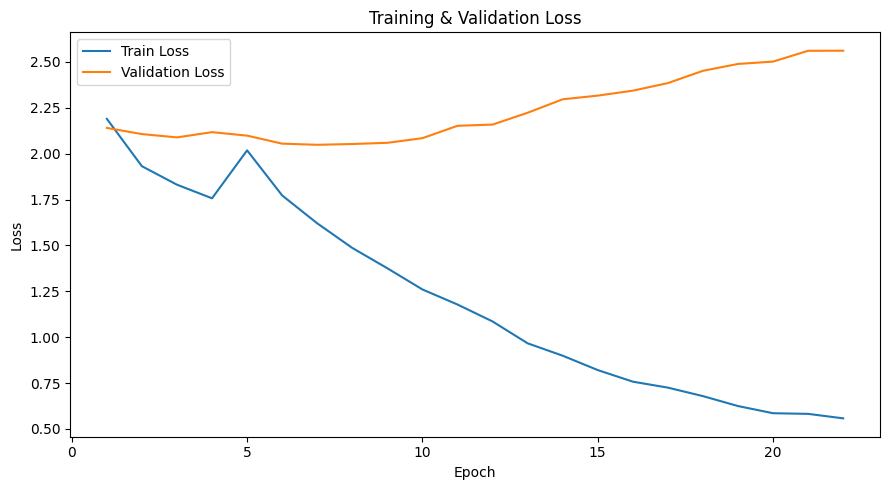

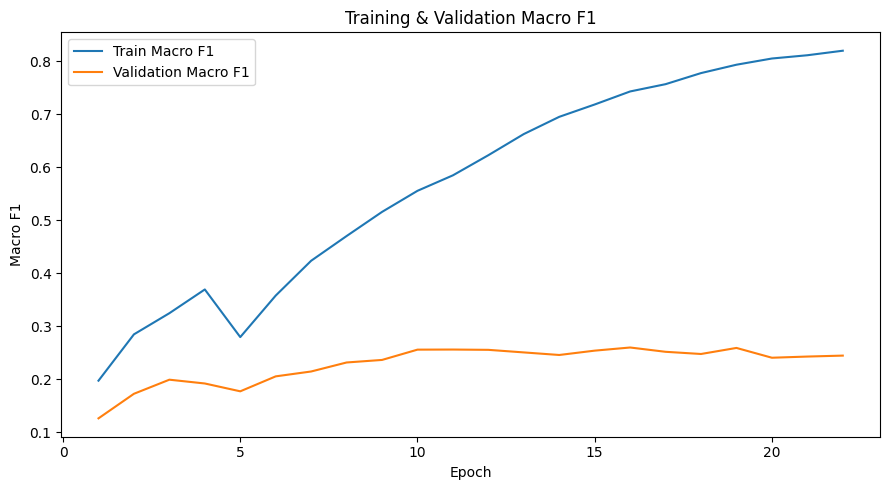

In [35]:
# ============================================================
# 30. TRAINING HISTORY & CURVES
# ============================================================

history_df = pd.DataFrame(history)

HISTORY_PATH = Path(
    f"/kaggle/working/{EXPERIMENT_ID}_training_history.csv"
)

history_df.to_csv(
    HISTORY_PATH,
    index=False,
)

display(
    history_df.tail(10)
)

plt.figure(figsize=(9, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss",
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Train Macro F1",
)
plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation Macro F1",
)
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("Training & Validation Macro F1")
plt.legend()
plt.tight_layout()
plt.show()

## 31. Final Evaluation — Official Test

Official test digunakan **hanya setelah** best checkpoint dipilih menggunakan
**CelebA-only validation dari official train**.

Tidak ada:
- training pada official test,
- scheduler berdasarkan official test,
- early stopping berdasarkan official test,
- pemilihan checkpoint berdasarkan official test.

Ini menjaga official test sebagai final unseen evaluation.

In [36]:
# ============================================================
# 31. LOAD BEST CHECKPOINT + OFFICIAL TEST
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

(
    test_metrics,
    y_true,
    y_pred,
    y_probs,
) = evaluate_loader(
    model,
    test_loader,
    criterion,
    return_probs=True,
)

# Weighted F1
_, _, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0,
    )
)

# Top-3 accuracy
top3_indices = np.argsort(
    y_probs,
    axis=1,
)[:, -3:]

top3_correct = np.array([
    true_label in row
    for true_label, row in zip(
        y_true,
        top3_indices,
    )
])

top3_accuracy = float(
    top3_correct.mean()
)

final_metrics = {
    "test_loss": test_metrics["loss"],
    "accuracy": test_metrics["accuracy"],
    "macro_precision": test_metrics["macro_precision"],
    "macro_recall": test_metrics["macro_recall"],
    "macro_f1": test_metrics["macro_f1"],
    "weighted_f1": float(weighted_f1),
    "top3_accuracy": top3_accuracy,
}

print("=" * 70)
print("OFFICIAL TEST RESULTS")
print("=" * 70)

for key, value in final_metrics.items():
    print(
        f"{key:18s}: {value:.4f}"
    )

OFFICIAL TEST RESULTS
test_loss         : 2.3049
accuracy          : 0.2818
macro_precision   : 0.2615
macro_recall      : 0.2535
macro_f1          : 0.2515
weighted_f1       : 0.2754
top3_accuracy     : 0.6294


## E3 Benchmark Comparison

E3 dibandingkan dengan:

### E0 Baseline
- Accuracy: 30.59%
- Macro Recall: 28.09%
- Macro F1: 27.00%
- Top-3: 63.49%

### E1+E2
- Accuracy: 26.86%
- Macro Recall: 24.35%
- Macro F1: 23.97%
- Top-3: 61.84%

### Paper FaRL16 — 12 Season + Sub-Type
- Accuracy: 31.8%
- Recall: 31.8%
- F1: 31.0%
- Top-3: 66.3%

In [37]:
# ============================================================
# E3 BENCHMARK COMPARISON
# ============================================================

baseline_E0 = {
    "accuracy": 0.3059,
    "macro_recall": 0.2809,
    "macro_f1": 0.2700,
    "top3_accuracy": 0.6349,
}

experiment_E1E2 = {
    "accuracy": 0.2686,
    "macro_recall": 0.2435,
    "macro_f1": 0.2397,
    "top3_accuracy": 0.6184,
}

paper_farl16 = {
    "accuracy": 0.318,
    "macro_recall": 0.318,
    "macro_f1": 0.310,
    "top3_accuracy": 0.663,
}

comparison_rows = []

for metric in [
    "accuracy",
    "macro_recall",
    "macro_f1",
    "top3_accuracy",
]:
    e3_value = final_metrics[metric]

    comparison_rows.append({
        "metric": metric,
        "E0_baseline": baseline_E0[metric],
        "E1E2": experiment_E1E2[metric],
        "current_experiment": e3_value,
        "paper_FaRL16": paper_farl16[metric],
        "current_vs_E0_pp": (
            e3_value - baseline_E0[metric]
        ) * 100,
        "current_vs_E1E2_pp": (
            e3_value - experiment_E1E2[metric]
        ) * 100,
        "current_vs_paper_pp": (
            e3_value - paper_farl16[metric]
        ) * 100,
    })

comparison_df = pd.DataFrame(
    comparison_rows
)

display(
    comparison_df.style.format({
        "E0_baseline": "{:.4f}",
        "E1E2": "{:.4f}",
        "current_experiment": "{:.4f}",
        "paper_FaRL16": "{:.4f}",
        "current_vs_E0_pp": "{:+.2f}",
        "current_vs_E1E2_pp": "{:+.2f}",
        "current_vs_paper_pp": "{:+.2f}",
    })
)

print(f"\nInterpretasi {EXPERIMENT_ID}:")

if final_metrics["accuracy"] > baseline_E0["accuracy"]:
    print(f"✅ {EXPERIMENT_ID} accuracy meningkat dibanding E0 baseline.")
else:
    print(
        "⚠️ {EXPERIMENT_ID} accuracy belum mengalahkan E0. Gap:",
        f"{(baseline_E0['accuracy'] - final_metrics['accuracy']) * 100:.2f} pp"
    )

if final_metrics["accuracy"] > paper_farl16["accuracy"]:
    print(f"✅ {EXPERIMENT_ID} accuracy melampaui benchmark FaRL16 paper.")
else:
    print(
        "ℹ️ {EXPERIMENT_ID} belum melampaui FaRL16. Gap:",
        f"{(paper_farl16['accuracy'] - final_metrics['accuracy']) * 100:.2f} pp"
    )

if final_metrics["macro_f1"] > baseline_E0["macro_f1"]:
    print(f"✅ {EXPERIMENT_ID} Macro F1 meningkat dibanding E0.")
else:
    print(f"⚠️ {EXPERIMENT_ID} Macro F1 belum meningkat dibanding E0.")

,metric,E0_baseline,E1E2,current_experiment,paper_FaRL16,current_vs_E0_pp,current_vs_E1E2_pp,current_vs_paper_pp
0,accuracy,0.3059,0.2686,0.2818,0.3180,-2.41,+1.32,-3.62
1,macro_recall,0.2809,0.2435,0.2535,0.3180,-2.74,+1.00,-6.45
2,macro_f1,0.2700,0.2397,0.2515,0.3100,-1.85,+1.18,-5.85
3,top3_accuracy,0.6349,0.6184,0.6294,0.6630,-0.55,+1.10,-3.36



Interpretasi E3:
⚠️ {EXPERIMENT_ID} accuracy belum mengalahkan E0. Gap: 2.41 pp
ℹ️ {EXPERIMENT_ID} belum melampaui FaRL16. Gap: 3.62 pp
⚠️ E3 Macro F1 belum meningkat dibanding E0.


In [38]:
# ============================================================
# 32. CLASSIFICATION REPORT + PER-CLASS RECALL
# ============================================================

target_names = [
    idx2class[i]
    for i in range(NUM_CLASSES)
]

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=target_names,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(
    report_dict
).T

display(
    report_df.loc[
        target_names,
        [
            "precision",
            "recall",
            "f1-score",
            "support",
        ]
    ].sort_values(
        "recall",
        ascending=False,
    )
)

REPORT_PATH = Path(
    f"/kaggle/working/{EXPERIMENT_ID}_classification_report.csv"
)

report_df.to_csv(
    REPORT_PATH
)

print(
    "Classification report saved:",
    REPORT_PATH
)

,precision,recall,f1-score,support
inverno_deep,0.394904,0.529915,0.452555,117.0
autunno_deep,0.408696,0.419643,0.414097,112.0
inverno_cool,0.329897,0.359551,0.344086,89.0
primavera_warm,0.300000,0.328767,0.313725,73.0
estate_light,0.322034,0.271429,0.294574,70.0
primavera_light,0.262295,0.250000,0.256000,64.0
autunno_warm,0.268657,0.243243,0.255319,74.0
inverno_bright,0.343750,0.189655,0.244444,58.0
estate_cool,0.106383,0.188679,0.136054,53.0
autunno_soft,0.126761,0.123288,0.125000,73.0


Classification report saved: /kaggle/working/E3_classification_report.csv


### Derived 4-season analysis

Ini **bukan** eksperimen 4-class yang setara dengan benchmark 4-season paper.
Prediksi 12-class hanya dipetakan kembali ke nama season untuk melihat apakah error utama
terjadi pada season atau subtype.

In [39]:
# ============================================================
# DERIVED 4-SEASON ANALYSIS FROM 12-CLASS PREDICTIONS
# ============================================================

idx_to_season = {
    idx: class_name.split("_")[0]
    for idx, class_name in idx2class.items()
}

season_true = np.array([
    idx_to_season[int(i)]
    for i in y_true
])

season_pred = np.array([
    idx_to_season[int(i)]
    for i in y_pred
])

derived_season_accuracy = float(
    np.mean(
        season_true == season_pred
    )
)

print(
    "Derived 4-season accuracy from 12-class output:",
    f"{derived_season_accuracy:.4f}"
)

print(
    "\nCatatan: ini hanya diagnostic aggregation, "
    "bukan direct 4-class benchmark."
)

Derived 4-season accuracy from 12-class output: 0.5066

Catatan: ini hanya diagnostic aggregation, bukan direct 4-class benchmark.


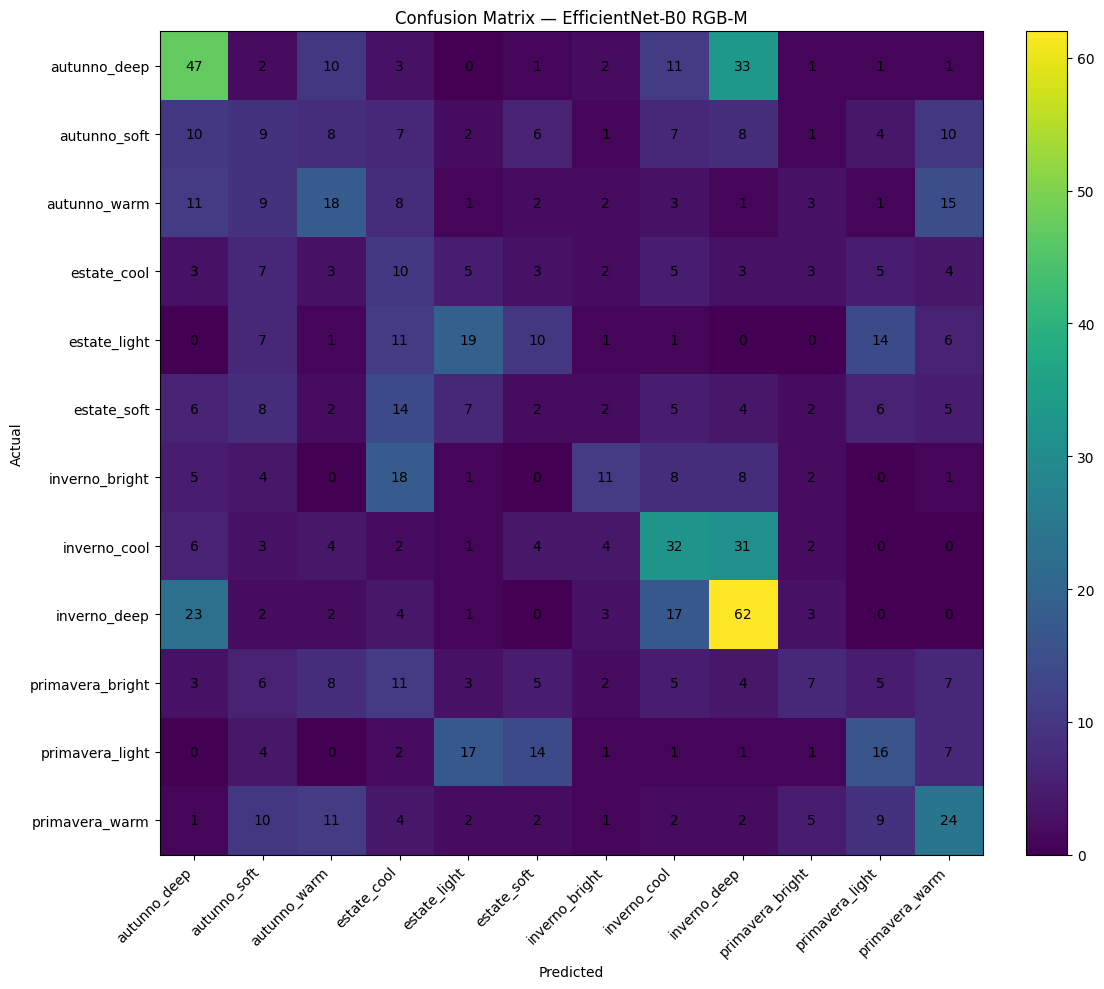

Saved: /kaggle/working/E3_confusion_matrix.png


In [40]:
# ============================================================
# 33. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
)

fig, ax = plt.subplots(
    figsize=(12, 10)
)

im = ax.imshow(cm)

ax.set_xticks(
    np.arange(NUM_CLASSES)
)
ax.set_yticks(
    np.arange(NUM_CLASSES)
)

ax.set_xticklabels(
    target_names,
    rotation=45,
    ha="right",
)
ax.set_yticklabels(
    target_names
)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(
    "Confusion Matrix — EfficientNet-B0 RGB-M"
)

# Cell labels
threshold = cm.max() / 2 if cm.max() > 0 else 0

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
        )

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04,
)

plt.tight_layout()

CM_PATH = Path(
    f"/kaggle/working/{EXPERIMENT_ID}_confusion_matrix.png"
)

plt.savefig(
    CM_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Saved:", CM_PATH)

In [41]:
# ============================================================
# 34. SAVE FINAL METRICS / TRAINING CONFIG
# ============================================================

FINAL_METRICS_PATH = Path(
    f"/kaggle/working/{EXPERIMENT_ID}_final_metrics.json"
)

final_payload = {
    **final_metrics,
    "best_epoch": checkpoint["best_epoch"],
    "best_val_macro_f1": checkpoint["best_val_macro_f1"],
    "num_classes": NUM_CLASSES,
    "class2idx": class2idx,
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "stage1_epochs": STAGE1_EPOCHS,
    "max_finetune_epochs": MAX_FINETUNE_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "head_lr": HEAD_LR,
    "backbone_lr": BACKBONE_LR,
    "classifier_lr": CLASSIFIER_LR,
    "weight_decay": WEIGHT_DECAY,
    "seed": SEED,
    "experiment_id": EXPERIMENT_ID,
    "experiment_name": EXPERIMENT_NAME,
    "hypothesis": EXPERIMENT_HYPOTHESIS,
    "validation_strategy": VALIDATION_STRATEGY,
    "use_foreground_crop": USE_FOREGROUND_CROP,
    "use_mild_color_aug": USE_MILD_COLOR_AUG,
    "unfreeze_last_n_blocks": UNFREEZE_LAST_N_BLOCKS,
    "dropout": DROPOUT,
}

with open(
    FINAL_METRICS_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        final_payload,
        f,
        indent=2,
    )

print("Artifacts:")
for path in [
    BEST_MODEL_PATH,
    HISTORY_PATH,
    REPORT_PATH,
    CM_PATH,
    FINAL_METRICS_PATH,
]:
    print("-", path)

print(f"\n✅ {EXPERIMENT_ID} SELESAI — {EXPERIMENT_NAME}")

Artifacts:
- /kaggle/working/E3_best_efficientnet_b0_rgbm.pth
- /kaggle/working/E3_training_history.csv
- /kaggle/working/E3_classification_report.csv
- /kaggle/working/E3_confusion_matrix.png
- /kaggle/working/E3_final_metrics.json

✅ E3 SELESAI — Source-Aware CelebA Validation + 5-Block Fine-Tuning


## Simpan konfigurasi eksperimen

File JSON ini membantu laporan dan reproduksi eksperimen.

In [42]:
# ============================================================
# SAVE MASTER EXPERIMENT CONFIG
# ============================================================

EXPERIMENT_CONFIG_PATH = Path(
    f"/kaggle/working/{EXPERIMENT_ID}_experiment_config.json"
)

experiment_config = {
    "experiment_id": EXPERIMENT_ID,
    "experiment_name": EXPERIMENT_NAME,
    "hypothesis": EXPERIMENT_HYPOTHESIS,
    "expected_advantage": EXPECTED_ADVANTAGE,
    "known_risk": KNOWN_RISK,

    "baseline_E0_accuracy": 0.3059,
    "E1E2_accuracy": 0.2686,

    "seed": SEED,
    "image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,

    "validation_strategy": VALIDATION_STRATEGY,
    "validation_fraction_of_official_train": (
        VAL_FRACTION_OF_OFFICIAL_TRAIN
    ),
    "validation_size": len(val_df),
    "validation_celeba_percent": (
        float(val_df["celeba"].mean()) * 100
    ),
    "official_test_celeba_percent": (
        float(test_df["celeba"].mean()) * 100
    ),

    "run_full_eda": RUN_FULL_EDA,
    "run_mask_audit": RUN_MASK_AUDIT,
    "run_dhash_screening": RUN_DHASH_SCREENING,

    "use_foreground_crop": USE_FOREGROUND_CROP,
    "use_mild_color_aug": USE_MILD_COLOR_AUG,

    "dropout": DROPOUT,
    "stage1_epochs": STAGE1_EPOCHS,
    "head_lr_stage1": HEAD_LR,
    "unfreeze_last_n_blocks": UNFREEZE_LAST_N_BLOCKS,
    "backbone_lr": BACKBONE_LR,
    "classifier_lr": CLASSIFIER_LR,
    "weight_decay": WEIGHT_DECAY,
    "max_finetune_epochs": MAX_FINETUNE_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,

    "selection_metric": "validation_macro_f1",
}

with open(
    EXPERIMENT_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        experiment_config,
        f,
        indent=2,
    )

print("Saved:", EXPERIMENT_CONFIG_PATH)

Saved: /kaggle/working/E3_experiment_config.json


# Version Notes Template

Setelah `Save & Run All` selesai, gunakan output paling bawah untuk melengkapi bagian ini
sebelum membuat Version berikutnya.

### Current experiment
- **Experiment ID:** lihat MASTER CONFIG
- **Hypothesis:** lihat MASTER CONFIG
- **Main change:** lihat MASTER CONFIG

### Result
- Accuracy:
- Macro Recall:
- Macro F1:
- Top-3:
- Best validation Macro F1:

### Kelebihan
- isi setelah evaluasi

### Kekurangan
- isi setelah evaluasi

### Kesimpulan
- apakah mengalahkan E0?
- apakah mendekati/melewati FaRL16?
- perubahan mana yang kemungkinan membantu atau merugikan?

### Next action
- E4 / E5 / E6 sesuai hasil.

In [43]:
# ============================================================
# AUTOMATIC VERSION SUMMARY
# ============================================================

delta_vs_e0_pp = (
    final_metrics["accuracy"] - 0.3059
) * 100

delta_vs_paper_pp = (
    final_metrics["accuracy"] - 0.318
) * 100

if final_metrics["accuracy"] > 0.3059:
    conclusion = "Accuracy meningkat dibanding E0 baseline."
else:
    conclusion = "Accuracy belum meningkat dibanding E0 baseline."

print("\n" + "=" * 84)
print("KAGGLE VERSION SUMMARY")
print("=" * 84)
print("Experiment       :", EXPERIMENT_ID, "-", EXPERIMENT_NAME)
print("Hypothesis       :", EXPERIMENT_HYPOTHESIS)
print("Expected benefit :", EXPECTED_ADVANTAGE)
print("Known risk       :", KNOWN_RISK)
print("-" * 84)
print(f"Best Val F1      : {checkpoint['best_val_macro_f1']:.4f}")
print(f"Official Accuracy: {final_metrics['accuracy']:.4f}")
print(f"Macro Recall     : {final_metrics['macro_recall']:.4f}")
print(f"Macro F1         : {final_metrics['macro_f1']:.4f}")
print(f"Top-3 Accuracy   : {final_metrics['top3_accuracy']:.4f}")
print(f"Δ vs E0          : {delta_vs_e0_pp:+.2f} pp")
print(f"Δ vs FaRL16      : {delta_vs_paper_pp:+.2f} pp")
print("Conclusion       :", conclusion)
print("=" * 84)

RUN_SUMMARY_PATH = Path(
    f"/kaggle/working/{EXPERIMENT_ID}_run_summary.json"
)

with open(
    RUN_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {
            "experiment_id": EXPERIMENT_ID,
            "experiment_name": EXPERIMENT_NAME,
            "hypothesis": EXPERIMENT_HYPOTHESIS,
            "expected_advantage": EXPECTED_ADVANTAGE,
            "known_risk": KNOWN_RISK,
            "best_val_macro_f1": checkpoint["best_val_macro_f1"],
            **final_metrics,
            "delta_accuracy_vs_E0_pp": delta_vs_e0_pp,
            "delta_accuracy_vs_FaRL16_pp": delta_vs_paper_pp,
            "conclusion": conclusion,
        },
        f,
        indent=2,
    )

print("Saved:", RUN_SUMMARY_PATH)


KAGGLE VERSION SUMMARY
Experiment       : E3 - Source-Aware CelebA Validation + 5-Block Fine-Tuning
Hypothesis       : CelebA-only validation yang lebih dekat dengan official test, dikombinasikan dengan 5-block fine-tuning, diharapkan meningkatkan generalization dibanding E0 dan E1+E2.
Expected benefit : Checkpoint selection lebih sesuai dengan domain official test; kapasitas adaptasi lebih besar daripada eksperimen 3-block.
Known risk       : CelebA-only validation mengurangi CelebA training pool dan model masih dapat overfit apabila 5-block fine-tuning terlalu agresif.
------------------------------------------------------------------------------------
Best Val F1      : 0.2598
Official Accuracy: 0.2818
Macro Recall     : 0.2535
Macro F1         : 0.2515
Top-3 Accuracy   : 0.6294
Δ vs E0          : -2.41 pp
Δ vs FaRL16      : -3.62 pp
Conclusion       : Accuracy belum meningkat dibanding E0 baseline.
Saved: /kaggle/working/E3_run_summary.json


In [44]:
import modellab_registry

# 1. Ekstrak hasil evaluasi yang sudah dihitung oleh notebook di sel sebelumnya
accuracy = final_metrics["accuracy"]
f1_score = final_metrics["macro_f1"]
precision = final_metrics["macro_precision"]
recall = final_metrics["macro_recall"]

# 2. Panggil fungsi auto-log, sertakan globals() dan panggil variabel konfigurasi master
modellab_registry.auto_log_experiment(
    env_globals=globals(),
    topic="topic-a",
    model="EfficientNet-B0",
    objective="Melakukan uji coba CelebA",
    dataset="deep_armocromia_prepared",
    owner="Fatih Itsbatul Haq"
)

===REGISTRY_PAYLOAD_START===
{"topic": "topic-a", "model": "EfficientNet-B0", "objective": "Melakukan uji coba CelebA", "dataset": "deep_armocromia_prepared", "owner": "Fatih Itsbatul Haq", "metrics": {"accuracy": 0.2817982456140351, "f1": 0.25145020417786296, "precision": 0.26146049305391444, "recall": 0.25349796779591266}}
===REGISTRY_PAYLOAD_END===
